<!-- d2l:prose id=hf-models-md-1 fw=all -->

# Pretrained Models with Hugging Face

The last time we ran weights that somebody else had trained, we wrote the
loader ourselves: a constructor call for our `GPT` class and a hand-written
map from the tensor names of the GPT-2 release to ours
(that section). Ask that model a question and it does what
it was trained to do: it continues the page. The models released today
answer the question, and nobody writes a loader for each of them any more. A
few lines of the Transformers library download a current open model and run
it.

Convenience of this kind answers none of the questions that this book has
taught us to ask. What did those lines download? How much memory will the
model need for a long prompt, or for many prompts at once? How fast can it
write? And will the same lines load the same model next month?

Since 2019 the Transformers library [@Wolf.Debut.Sanh.ea.2020] has put
many architectures behind one loading interface. Its companion, the Hugging
Face Hub, stores each model as a git repository that holds a configuration
file, a tokenizer and the tensors. The code that runs the model is part of
the library, and the configuration tells the library which code to run and
with which shapes. The configuration is therefore the blueprint of the
model: every shape follows from it.

Later chapters of this part load such a *checkpoint*, as a released set of
weights is called, again and again, and the first questions are always
whether it fits on the GPU and how fast it runs. The configuration goes a
long way towards both answers before a single tensor is downloaded. It gives
the bytes of the weights and of the cache exactly, it lets us estimate the
rest of the memory, and it puts a lower bound on the time per token.

We read the repositories of two current models, Qwen3.5-2B from Alibaba and
Gemma 4 E2B from Google. Both are small enough to run on one consumer GPU,
and neither is a plain transformer, which is the reason to read both. We
read until every field of their configurations points to something we built
earlier in this book and to a number of bytes. Then we put the models on one
GPU, an RTX 4090 with 24 GB of memory, and measure how well those numbers
predict memory and speed. The section is long. Its first half reads, and its
second half measures.

One line has to come before the imports, an option of PyTorch's memory
allocator.

In [1]:
import os
# The allocator reads this setting when CUDA starts, so it comes first:
# expandable segments grow in place instead of being fixed in size, so a
# large tensor need not find one free block that fits it
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

In [2]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [3]:
import accelerate
import collections
import functools
import gc
import huggingface_hub
import itertools
import json
import pandas as pd
import re
import transformers
from huggingface_hub import HfApi, file_exists
from safetensors import safe_open
from transformers import (AutoConfig, AutoModelForCausalLM, AutoTokenizer,
                          GenerationConfig)

<!-- d2l:prose id=hf-models-md-2 fw=all -->

## A First Load

The next cell names the two models, a third whose tokenizer we will compare
with theirs, and the question we will ask. Without a GPU it replaces
Qwen3.5-2B by its smallest sibling in fp32, and the measurements of the
second half are skipped. One line of setup, `d2l.bind_hf_kernels()`, chooses
the GPU code that runs the models, a matter for the second half. The cell
prints the versions of the libraries, which belong to the record of any
result: the modeling code lives in the library, so another version may run
the same tensors along a different path.

In [4]:
QWEN, GEMMA = 'Qwen/Qwen3.5-2B', 'google/gemma-4-E2B-it'
QWEN3 = 'Qwen/Qwen3-0.6B'  # its tokenizer only
NAMES = {QWEN3: 'Qwen3-0.6B', QWEN: 'Qwen3.5-2B', GEMMA: 'Gemma 4 E2B'}
GPU = torch.cuda.is_available()
# On a GPU the studied model runs in bf16; without one, its smallest sibling
# runs in fp32 and the measurements of the last part are skipped
RUN_MODEL, RUN_REV, RUN_DTYPE = (
    (QWEN, '15852e8c16360a2fea060d615a32b45270f8a8fc', torch.bfloat16) if GPU
    else ('Qwen/Qwen3.5-0.8B', '2fc06364715b967f1860aea9cf38778875588b17',
          torch.float32))
QUESTION = ('Why does a language model keep a key-value cache when it '
            'generates text?')
d2l.bind_hf_kernels()  # fused kernels for CUDA bf16, reference code otherwise
transformers.logging.set_verbosity_error()  # no notices or progress bars
transformers.logging.disable_progress_bar()
huggingface_hub.utils.disable_progress_bars()
huggingface_hub.utils.logging.set_verbosity_error()
for module in (torch, transformers, huggingface_hub, accelerate):
    print(f'{module.__name__} {module.__version__}')

torch 2.11.0+cu128
transformers 5.22.2
huggingface_hub 2.4.0
accelerate 1.15.0


<!-- d2l:prose id=hf-models-md-3 fw=all -->

First the model we already have. GPT-2 gets the question in a form that a
web page might use and writes 32 tokens greedily.

In [5]:
gpt2, enc = d2l.load_gpt2().to(d2l.try_gpu()), d2l.gpt2_tokenizer()
out = gpt2.generate(enc.encode(f'Q: {QUESTION}\nA:'), 32, top_k=1)
d2l.print_wrapped(enc.decode(out))
del gpt2

Q: Why does a language model keep a key-value cache when it generates text?
A: The key-value cache is a way to store data in a database. It is a way to
    store data in a database that is not stored in a key


<!-- d2l:prose id=hf-models-md-4 fw=all -->

GPT-2 writes fluent text about the nearest topic it knows, databases, and
begins to repeat itself. Now a current model. Three functions do the work,
and the rest of the cell is formatting. `from_pretrained` loads the
tokenizer and the model, each by the name of its repository and a
`revision`, which fixes the version of the files. Its argument `dtype` asks
for bf16, the 16-bit format of that section with half the
bytes of fp32, and `device_map` says where the weights go.
`apply_chat_template` wraps the question in the format the model was trained
to answer, and with `add_generation_prompt` the prompt ends where the
model's reply begins. `generate` then writes 64 tokens greedily.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(RUN_MODEL, revision=RUN_REV)
model = AutoModelForCausalLM.from_pretrained(
    RUN_MODEL, revision=RUN_REV, dtype=RUN_DTYPE, device_map=d2l.try_gpu())
prompt = tokenizer.apply_chat_template(
    [{'role': 'user', 'content': QUESTION}], add_generation_prompt=True,
    enable_thinking=False, return_dict=True,
    return_tensors='pt').to(model.device)
reply = model.generate(**prompt, max_new_tokens=64, do_sample=False)
n_prompt = prompt['input_ids'].shape[1]
d2l.print_wrapped(tokenizer.decode(reply[0, n_prompt:],
                                   skip_special_tokens=True))
print(f'{type(model).__name__}: {model.num_parameters():,} parameters')

Language models (like those in LLMs) use a **key-value cache** (often called
    a **context window** or **attention mechanism**) primarily to balance
    **computational efficiency** with **memory constraints**. Here's why
    it's essential:

### 1. **Efficient Context Processing**
   -
Qwen3_5ForCausalLM: 1,881,825,088 parameters


<!-- d2l:prose id=hf-models-md-5 fw=all -->

This reply has the form of an answer. It addresses the question and starts a
list of reasons before its 64 tokens run out. Whether its content is right
is another matter (a key-value cache is not "often called a context
window"), and judging content takes the tools of later sections. Here we
care about what we loaded, and the last line gives us a number to start
from: the model called Qwen3.5-2B has 1.88 billion parameters.

## Checkpoints on the Hub

To say what we loaded, we have to open the repository behind the model id
`Qwen/Qwen3.5-2B`. Its files can change under the same name, so we first fix
its contents. Then we look at what it contains and at what a load takes from
it.

### Revisions and Licenses

A model id names a repository, and the files of a repository change: authors
correct a chat template, replace a tokenizer file, or upload new weights
under the old name. The hardest of these to notice is the corrected
template. The tensors stay the same, the model reads a different prompt, and
last month's score cannot be reproduced. A *revision* names one commit by
its 40-digit hash, and a commit never changes
(that section). The load above passed the same revision
to the model and to the tokenizer, whose files include the chat template.
`HF_REVISIONS` pins every model of this chapter to the commit it was written
against, in November 2026. Later sections add their own entries.

In [7]:

HF_REVISIONS = {
    'Qwen/Qwen3-0.6B': 'c1899de289a04d12100db370d81485cdf75e47ca',
    'Qwen/Qwen3-0.6B-Base': 'da87bfb608c14b7cf20ba1ce41287e8de496c0cd',
    'Qwen/Qwen3-1.7B': '70d244cc86ccca08cf5af4e1e306ecf908b1ad5e',
    'Qwen/Qwen3-1.7B-Base': 'ea980cb0a6c2ae4b936e82123acc929f1cec04c1',
    'Qwen/Qwen3-4B': '1cfa9a7208912126459214e8b04321603b3df60c',
    'Qwen/Qwen3-8B': 'b968826d9c46dd6066d109eabc6255188de91218',
    'Qwen/Qwen3.5-0.8B': '2fc06364715b967f1860aea9cf38778875588b17',
    'Qwen/Qwen3.5-0.8B-Base': 'dc7cdfe2ee4154fa7e30f5b51ca41bfa40174e68',
    'Qwen/Qwen3.5-2B': '15852e8c16360a2fea060d615a32b45270f8a8fc',
    'Qwen/Qwen3.5-4B': '851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a',
    'google/gemma-4-E2B-it': '4adf15748de9e1a0097b6274cee9c15836c41c37'}

<!-- d2l:prose id=hf-models-md-6 fw=all -->

For each pin, the Hub reports the license at that commit and the size of the
weight files.

In [8]:
for m, rev in HF_REVISIONS.items():  # licence and weights at each pin
    card = HfApi().model_info(m, revision=rev, files_metadata=True)
    size = sum(f.size for f in card.siblings
               if f.rfilename.endswith('.safetensors'))
    print(f'{m:24} {rev[:12]}  {card.card_data.license:12} '
          f'{size / 1e9:5.2f} GB')

Qwen/Qwen3-0.6B          c1899de289a0  apache-2.0    1.50 GB


Qwen/Qwen3-0.6B-Base     da87bfb608c1  apache-2.0    1.19 GB


Qwen/Qwen3-1.7B          70d244cc86cc  apache-2.0    4.06 GB


Qwen/Qwen3-1.7B-Base     ea980cb0a6c2  apache-2.0    3.44 GB


Qwen/Qwen3-4B            1cfa9a720891  apache-2.0    8.04 GB


Qwen/Qwen3-8B            b968826d9c46  apache-2.0   16.38 GB


Qwen/Qwen3.5-0.8B        2fc06364715b  apache-2.0    1.75 GB


Qwen/Qwen3.5-0.8B-Base   dc7cdfe2ee41  apache-2.0    1.75 GB


Qwen/Qwen3.5-2B          15852e8c1636  apache-2.0    4.55 GB


Qwen/Qwen3.5-4B          851bf6e806ef  apache-2.0    9.32 GB


google/gemma-4-E2B-it    4adf15748de9  apache-2.0   10.25 GB


<!-- d2l:prose id=hf-models-md-7 fw=all -->

All eleven repositories carry the Apache 2.0 license at their pins, which
allows use and redistribution, commercial use included. A repository can
change its license from one revision to the next, so the license belongs in
the record next to the commit. None of the eleven is *gated* either: a gated
repository serves its files only to an account that has accepted its terms.

Names that end in `-Base` are *base* models, trained only to continue text.
The others were *post-trained* by their authors to follow instructions and
to hold a conversation.

The last column holds a puzzle. Our load of Qwen3.5-2B reported 1.88 billion
parameters, which are 3.76 GB at two bytes each, and the weight file takes
4.55 GB. Gemma 4 E2B carries the same "2B" in its name, and its file takes
10.25 GB. We will account for both down to the last tensor.

The book's own data files are pinned in the same way: they are published at
`LM_DATA_URL` under names that carry a version, and `DATA_HUB` records the
SHA-1 hash of each. The first entry holds the data of this section's last
plot, so that a reader without a GPU can still draw it.

In [9]:

LM_DATA_URL = 'https://d2l-data.smola.org/lm/'

In [10]:

d2l.DATA_HUB['lm-hf-memory-speed-v2'] = (  # fused kernels (fla, flex_sdpa)
    d2l.LM_DATA_URL + 'lm-hf-memory-speed-v2.json',
    'e1a6407448d04a3aef8cc6fff5ed39cfea549f0b')

<!-- d2l:prose id=hf-models-md-8 fw=all -->

### Repository Anatomy

Let us look inside the pinned commit of Qwen3.5-2B.

In [11]:
info = HfApi().model_info(QWEN, revision=d2l.HF_REVISIONS[QWEN],
                          files_metadata=True)
for file in info.siblings:
    print(f'{file.size / 1e6:10,.2f} MB  {file.rfilename}')
print(f'safetensors: {info.safetensors.total:,} elements')

      0.00 MB  .gitattributes
      0.01 MB  LICENSE
      0.06 MB  README.md
      0.01 MB  chat_template.jinja
      0.00 MB  config.json
      3.35 MB  merges.txt
  4,548.22 MB  model.safetensors-00001-of-00001.safetensors
      0.06 MB  model.safetensors.index.json
      0.00 MB  preprocessor_config.json
     12.81 MB  tokenizer.json
      0.02 MB  tokenizer_config.json
      0.00 MB  video_preprocessor_config.json
      6.72 MB  vocab.json
safetensors: 2,274,069,824 elements


<!-- d2l:prose id=hf-models-md-9 fw=all -->

One of the thirteen files is more than 99% of the repository. `config.json`
holds the shapes. `README.md` is the *model card*, the authors' description
of the model, of its intended use and of its benchmark results.
`tokenizer.json` and `tokenizer_config.json` define the tokenizer
(`vocab.json` and `merges.txt` repeat it in the older format of GPT-2),
`chat_template.jinja` wrapped our question, and the two preprocessor files
describe image and video inputs: this model also reads pictures. The weights
are in a single *shard*, a safetensors file, next to an index that maps
tensor names to shards. Larger models have several shards. One file is
absent: many repositories carry a `generation_config.json` with default
sampling settings, and this one has none. the figure shows
which part of the library reads which file.

![What the repository of Qwen3.5-2B holds at one commit, and which loader reads each file. The dashed file is optional and absent here. The modeling code is part of the library, not of the repository. Reading the header of a shard takes two small range requests and no tensor data.](../img/mdl-lm-pretrained-hub-repo.svg)

The last line of the output counts 2,274,069,824 elements. At two bytes each
they take 4,548 MB, the size of the shard, so the file holds 16-bit numbers
and little else. Which tensors do they form? The answer does not need the
file, which is welcome for a model that we have not downloaded yet. A
safetensors file starts with an 8-byte integer, the length of a JSON header
that lists the name, dtype, shape and byte range of every tensor
(that section). An HTTP *range request* asks a server for a span
of bytes of a file, so two of them per shard return every shape and no
tensor data. `safetensors_header` does this for a pinned repository. The
format is all in its last loop: eight bytes give the length of the header,
and that many bytes of JSON follow. The lines before the loop deal with
access to sharded and to gated repositories, and
`huggingface_hub.get_safetensors_metadata` does the same job in production
code.

In [12]:

def safetensors_header(model_id, revision=None, timeout=30):
    """Shape and dtype of every tensor of a Hub checkpoint, read by HTTP
    range requests without fetching tensor data (in production:
    `huggingface_hub.get_safetensors_metadata`)."""
    import urllib.error
    import urllib.request
    import huggingface_hub
    revision = revision or d2l.HF_REVISIONS.get(model_id)
    if revision is None:
        revision = huggingface_hub.HfApi().model_info(model_id).sha
        print(f'unpinned: {model_id}@{revision}')
    token = huggingface_hub.get_token()  # for gated repositories

    class HubRedirect(urllib.request.HTTPRedirectHandler):
        """Keep the token on redirects within the Hub, not to the CDN."""
        def redirect_request(self, request, *args):
            new = super().redirect_request(request, *args)
            auth = request.unredirected_hdrs.get('Authorization')
            if new and auth and new.host == request.host:
                new.add_unredirected_header('Authorization', auth)
            return new

    opener = urllib.request.build_opener(HubRedirect)

    def fetch(filename, start=None, stop=None):  # bytes start, ..., stop - 1
        request = urllib.request.Request(huggingface_hub.hf_hub_url(
            model_id, filename, revision=revision))
        if start is not None:
            request.add_header('Range', f'bytes={start}-{stop - 1}')
        if token:  # unredirected: dropped when a redirect leaves the Hub
            request.add_unredirected_header('Authorization', f'Bearer {token}')
        with opener.open(request, timeout=timeout) as response:
            if start is None or response.status == 206:
                return response.read()
            return response.read(stop)[start:]  # the server ignored the range

    try:  # a sharded checkpoint lists its shards in an index
        index = json.loads(fetch('model.safetensors.index.json'))
        shards = sorted(set(index['weight_map'].values()))
    except urllib.error.HTTPError as e:
        if e.code != 404:
            raise
        shards = ['model.safetensors']
    tensors = {}
    for shard in shards:
        n = int.from_bytes(fetch(shard, 0, 8), 'little')  # header length
        header = json.loads(fetch(shard, 8, 8 + n))
        header.pop('__metadata__', None)
        tensors.update({name: (tuple(t['shape']), t['dtype'])
                        for name, t in header.items()})
    return tensors

<!-- d2l:prose id=hf-models-md-10 fw=all -->

We read the header of Qwen3.5-2B, group its tensors by the first part of
their names, and count the elements of each group.

In [13]:
def top_prefix(name):  # model.language_model, model.visual or mtp
    return '.'.join(name.split('.')[:2 if name.startswith('model.') else 1])

header = safetensors_header(QWEN)
elements = collections.Counter()
for name, (shape, dtype) in header.items():
    elements[top_prefix(name)] += math.prod(shape)
dtypes = collections.Counter(dtype for _, dtype in header.values())
print(f'{len(header)} tensors {dict(dtypes)}, '
      f'{sum(elements.values()):,} elements')
for prefix, n in elements.items():
    print(f'{n:15,}  {prefix}')
assert sum(elements.values()) == info.safetensors.total

632 tensors {'F32': 36, 'BF16': 596}, 2,274,069,824 elements
  1,881,825,088  model.language_model
    331,416,576  model.visual
     60,828,160  mtp


<!-- d2l:prose id=hf-models-md-11 fw=all -->

The file holds three things. The language model has the 1,881,825,088
elements that the first load reported as parameters. A *vision tower*, as an
encoder for images attached to a language model is called, has 331 million
parameters. A head of 61 million (`mtp`) serves multi-token prediction, the
prediction of tokens beyond the next one
[@Gloeckle.Idrissi.Roziere.ea.2024]. Serving engines, the programs that
run a model for many users at once, can use it to draft several tokens in
one step, and `generate` ignores it. All but 36 small tensors are stored in
bf16. So the "2B" of the name counts neither what the file holds, 2.27
billion elements, nor what a text model loads. A model card rounds. The
header does not.

### Pinned Loading and the Text Model

We want the language model alone, and loading a part of a checkpoint can
fail silently. A loader that finds no tensor for a module warns and leaves
the module at its random initialization, and the parameter count looks right
all the same. A *multimodal* file, one that also holds models for images or
sound, invites this accident. Let us see how.

The classes of Transformers whose names begin with `Auto` pick the class to
build from the field `model_type` of the configuration. Asked for a causal
language model, they build the text model for Qwen3.5, which is why the
first load printed `Qwen3_5ForCausalLM`. For Gemma 4 they build the whole
multimodal model, towers included. To get its text model alone, we have to
hand them the configuration of the language model by itself
(`get_text_config`). Now the names no longer match. In the file, the tensors
of the language model carry a prefix, `model.language_model`, that a text
model does not expect. For Qwen3.5 the library translates the names by
itself. For Gemma 4 it does not, and the text model would find none of its
tensors.

The function `load_hf` wraps the loading call for the rest of this part, and
its first job is to rule this accident out. It passes the configuration of
the language model, so that the towers stay on disk, and the translation of
names where the file needs one (`key_mapping`). Then it raises an error if
any tensor of the model is still missing. If one line of the function is to
be remembered, it is that one.

The other guards are quickly told. `load_hf` passes the revision from
`HF_REVISIONS` to the configuration, the model and the tokenizer. It refuses
repositories that bring their own Python (`trust_remote_code=False`) and
weights in pickle format, which can execute code when they are loaded
(`use_safetensors=True`, that section). On a machine
with one GPU it places every module there, because a model spread over the
GPU and the CPU runs without an error, and very slowly. And it completes the
list of tokens at which `generate` stops, for a reason that
that section gives.

The function ends with a *load report* of three items: the class that was
built and its stop tokens, the tensors of the file that the model ignored,
and the GPU programs, called *kernels*, that the model runs. We define the
function here, next to the accident it prevents, and read its first report
when we load Gemma 4 E2B, the model that needs it.

In [14]:

def load_hf(model_id, revision=None, dtype=torch.bfloat16, device_map='auto',
            *, attn_implementation=None):
    """A pinned causal language model from the Hugging Face Hub, text part
    only, in eval mode, and its tokenizer; prints a load report and the
    kernels it runs. The tokenizer's end token joins the stop tokens of
    `generate`; the attention defaults to `d2l.hf_attention`'s choice."""
    import collections
    import warnings
    import transformers
    if revision is None:
        revision = d2l.HF_REVISIONS.get(model_id)
    if revision is None:
        import huggingface_hub
        revision = huggingface_hub.HfApi().model_info(model_id).sha
        print(f'unpinned: {model_id}@{revision}')
    if device_map == 'auto':  # one GPU: everything on it; none: the CPU
        n_gpus = torch.cuda.device_count()
        device_map = ('cpu' if n_gpus == 0 else {'': 0} if n_gpus == 1
                      else 'auto')
    pin = dict(revision=revision, trust_remote_code=False)
    config = transformers.AutoConfig.from_pretrained(model_id, **pin)
    text = config.get_text_config()  # the language model's configuration
    renames = {}
    if text is not config and text.model_type in d2l._TEXT_KEY_MAPPING:
        renames['key_mapping'] = d2l._TEXT_KEY_MAPPING[text.model_type]
    d2l.bind_hf_kernels()  # routes fused kernels, registers flex_sdpa
    if attn_implementation is None:  # the device of the first module
        device = (next(iter(device_map.values()))
                  if isinstance(device_map, dict) else device_map)
        attn_implementation = d2l.hf_attention(
            text, 0 if device == 'auto' else device)
    model, info = transformers.AutoModelForCausalLM.from_pretrained(
        model_id, config=text, dtype=dtype, device_map=device_map,
        attn_implementation=attn_implementation, use_safetensors=True,
        output_loading_info=True, **pin, **renames)
    if info['missing_keys']:  # these modules would stay randomly initialized
        del model  # a kept traceback would otherwise hold its memory
        raise RuntimeError(f'no weights for {sorted(info["missing_keys"])}')
    model.revision = revision
    tokenizer = transformers.AutoTokenizer.from_pretrained(model_id, **pin)
    # Without generation_config.json, `generate` stops only at the
    # configuration's end token, which need not be the one ending a chat turn
    stop = model.generation_config.eos_token_id
    stop = ([] if stop is None else [stop] if isinstance(stop, int)
            else list(stop))
    if tokenizer.eos_token_id not in [*stop, None]:
        stop.append(tokenizer.eos_token_id)
        model.generation_config.eos_token_id = stop
    unexpected = collections.Counter(  # keys in the file the model ignores
        '.'.join(key.split('.')[:2]) for key in info['unexpected_keys'])
    print(f'{model_id}@{revision[:12]}: {type(model).__name__}, '
          f'stop tokens {stop}')
    print('0 missing keys; unexpected keys:',
          '(not loaded)' if unexpected else 'none')
    if unexpected:  # by count, then name
        d2l.print_wrapped('    ' + ', '.join(f'{k} {n:,}' for k, n in sorted(
            unexpected.items(), key=lambda kv: (-kv[1], kv[0]))), width=96)
    print('kernels:', ', '.join(f'{k} {v}'
                                for k, v in d2l.hf_kernels(model).items()))
    devices = set(getattr(model, 'hf_device_map', {}).values())
    if len(devices) > 1:
        warnings.warn(f'{model_id} is spread over {sorted(map(str, devices))}')
    return model.eval(), tokenizer

<!-- d2l:prose id=hf-models-md-12 fw=all -->

Qwen3.5-2B is already in memory, loaded by the plain call of our first load,
and we do not load it a second time. We check that load against the pin
instead, with two questions. Does the model on the GPU hold the tensors of
the pinned file? And does every tensor of the model have a counterpart in
that file? The first is a spot check. It compares the two places where we
wrote the hash, and one tensor on the GPU with its copy in the file. The
second is the accident just described.

In [15]:
assert RUN_REV == HF_REVISIONS[RUN_MODEL]
# A pinned load reads its files from a cache folder named after the commit;
# the loaded model holds the tensors of that folder's weights file
key = 'model.language_model.norm.weight'
index = huggingface_hub.hf_hub_download(
    RUN_MODEL, 'model.safetensors.index.json', revision=RUN_REV)
with open(index) as f:
    path = huggingface_hub.hf_hub_download(
        RUN_MODEL, json.load(f)['weight_map'][key], revision=RUN_REV)
with safe_open(path, 'pt') as f:
    pinned = f.get_tensor(key)
assert torch.equal(pinned.to(model.dtype), model.model.norm.weight.cpu())
run_header = safetensors_header(RUN_MODEL)
in_file = sum(math.prod(shape) for shape, _ in run_header.values())
loaded = model.num_parameters()
# Every tensor of the model has its counterpart in the file, where the text
# model's names start with model.language_model; the output layer shares
# the embedding's tensor
tied = {'lm_head.weight'} if model.config.tie_word_embeddings else set()
names = {re.sub(r'^model\.', 'model.language_model.', name)
         for name in model.state_dict().keys() - tied}
assert names <= run_header.keys()
print(os.path.relpath(os.path.dirname(path),
                      huggingface_hub.constants.HF_HUB_CACHE))
print(f'{key} from that file = the loaded tensor, on '
      f'{sorted({str(p.device) for p in model.parameters()})}')
print(f'{loaded:,} parameters loaded, {in_file:,} elements in the file, '
      f'{in_file - loaded:,} left on disk')

models--Qwen--Qwen3.5-2B/snapshots/15852e8c16360a2fea060d615a32b45270f8a8fc
model.language_model.norm.weight from that file = the loaded tensor, on ['cuda:0']
1,881,825,088 parameters loaded, 2,274,069,824 elements in the file, 392,244,736 left on disk


<!-- d2l:prose id=hf-models-md-13 fw=all -->

Yes to both. The tensor read from the cache folder of the pinned commit
equals the one on the GPU, and every tensor of the model has its counterpart
in the file under the prefix `model.language_model`, except the output
layer, which shares the embedding matrix. What stays on disk is the vision
tower and the head for multi-token prediction, 392 million elements. At two
bytes each they are the 0.8 GB that separated the file from the model.

## Tokenizers and Generation

Between the text we type and the tensors we loaded stand two more files of
the repository, the tokenizer and the chat template. Between the logits and
the text the model writes stand the arguments of `generate`.

### Tokenizers and Chat Templates

The same text costs a different number of tokens in every vocabulary. We
compare four tokenizers: that of GPT-2, those of our two models, and that of
Qwen3-0.6B, from the family before Qwen3.5, which later sections use. All
four split text into subword tokens, like the byte-pair encoding of
that section. For each we count the vocabulary and the tokens
it spends per character on the opening of *The Time Machine*, on the first
20,000 characters of this book's library, and on a Chinese paragraph about
the key-value cache.

In [16]:
CHINESE = ('语言模型每次只生成一个词元。为了预测下一个词元，它要用到前面所有词元的'
           '信息。键值缓存把每一层已经算好的键和值保存下来，生成新词元时只需计算这'
           '一个位置，而不必从头处理整段文本。上下文越长，缓存占用的显存就越多，所以'
           '长文本推理常常受限于内存，而不是算力。')
fname = d2l.download(d2l.DATA_URL + 'timemachine.txt', '../data',
                     '090b5e7e70c295757f55df93cb0a180b9691891a')
with open(fname, encoding='utf-8') as f:
    book = f.read()
with open(d2l.__file__, encoding='utf-8') as f:
    library = f.read()
texts = {'The Time Machine': book[:20000], 'd2l/torch.py': library[:20000],
         'Chinese': CHINESE}

def per_char(encode, texts):  # tokens per character of each text
    return {name: len(encode(text)) / len(text)
            for name, text in texts.items()}

table = {'GPT-2': {'vocabulary': enc.n_vocab, 'embedding rows': enc.n_vocab,
                   **per_char(enc.encode_ordinary, texts)}}
tokenizers = {}
for m in (QWEN3, QWEN, GEMMA):
    tokenizers[m] = AutoTokenizer.from_pretrained(m, revision=HF_REVISIONS[m])
    rows = AutoConfig.from_pretrained(
        m, revision=HF_REVISIONS[m]).get_text_config().vocab_size
    encode = functools.partial(tokenizers[m].encode, add_special_tokens=False)
    table[NAMES[m]] = {'vocabulary': len(tokenizers[m]),
                       'embedding rows': rows, **per_char(encode, texts)}
table = pd.DataFrame(table).T.astype({'vocabulary': int,
                                     'embedding rows': int})
print(table.round(2).to_string())

             vocabulary  embedding rows  The Time Machine  d2l/torch.py  Chinese
GPT-2             50257           50257              0.25          0.45     2.17
Qwen3-0.6B       151669          151936              0.24          0.24     0.70
Qwen3.5-2B       248077          248320              0.24          0.25     0.64
Gemma 4 E2B      262144          262144              0.24          0.29     0.67


<!-- d2l:prose id=hf-models-md-14 fw=all -->

On English prose the four agree: about a quarter of a token per character.
On other text they part. GPT-2 spends one and a half to two times as many
tokens on Python code as the newer tokenizers do, and more than two tokens
per Chinese character on average, where the others need about two thirds of
one. The vocabulary column says why. GPT-2 built its 50,257 tokens from
English web text. It spends one token on every space of an indentation, and
a Chinese character, three bytes in UTF-8, falls apart into pieces. The
newer vocabularies are three to five times as large, with tokens for runs
of spaces and for the characters of many languages. The ratio matters
because it converts every per-token quantity of this section, bytes of cache
or milliseconds of decoding, into a quantity per character of text.

One detail of the table enters the counts below. The embedding matrices of
the Qwen models have a few hundred more rows than their tokenizers have
tokens, spare rows that no token maps to. The number of rows, `vocab_size`,
is what a parameter count needs.

What did Qwen3.5-2B read when we asked it our question? Not the question
alone: `apply_chat_template` renders the conversation with the template in
`chat_template.jinja`. We print the result and the ids of its last nine
tokens.

In [17]:
def chat(tok, content):  # one user turn, rendered for generation
    return tok.apply_chat_template(
        [{'role': 'user', 'content': content}], add_generation_prompt=True,
        enable_thinking=False, return_dict=True, return_tensors='pt')

chat_ids = chat(tokenizers[QWEN], QUESTION)['input_ids'][0]
print(tokenizers[QWEN].decode(chat_ids))
tail = chat_ids[-9:].tolist()
print(tail)
print(tokenizers[QWEN].convert_ids_to_tokens(tail))

<|im_start|>user
Why does a language model keep a key-value cache when it generates text?<|im_end|>
<|im_start|>assistant
<think>

</think>


[248046, 198, 248045, 74455, 198, 248068, 271, 248069, 271]
['<|im_end|>', 'Ċ', '<|im_start|>', 'assistant', 'Ċ', '<think>', 'ĊĊ', '</think>', 'ĊĊ']


<!-- d2l:prose id=hf-models-md-15 fw=all -->

The markers `<|im_start|>` and `<|im_end|>` open and close a turn, each as a
single token (`Ċ` displays a newline). The prompt ends inside the
assistant's turn, which is why the model answers the question and does not
continue it. More exactly, it ends after an empty `<think>` block. Qwen
models can write out reasoning before they answer, and the template, not the
weights, switches this on and off: with `enable_thinking=False` the template
closes the block itself. The default differs between checkpoints, even
within one family, so every helper in this part passes `enable_thinking`
explicitly. Templates, roles and the difference between base and
post-trained checkpoints are the subject of that section.

### Generation Arguments and Defaults

`generate` is the loop of that section: compute the logits of the
next token, choose a token, append it, and stop at a *stop token*, which is
any token on a list that comes with the model. Its arguments are the
settings of our `sample_next` under other names
(the table).

<!-- tbl-caption:The sampling arguments of `generate` in Transformers and their counterparts in the sampler of that section. -->

| `generate` | `sample_next` | effect |
|---|---|---|
| `do_sample=False` | `temperature=0` | greedy: take the most probable token |
| `temperature` | `temperature` | divide the logits before the softmax |
| `top_k` | `k` | keep the $k$ most probable tokens |
| `top_p` | `p` | keep the smallest set of most probable tokens whose total probability reaches $p$ |
| `min_p` | `min_p` | keep tokens with at least this fraction of the top probability |

The two samplers differ where truncations combine. Transformers applies each
truncation to the renormalized distribution that the previous one left,
whereas `sample_next` computes every cutoff on the full distribution, so
Transformers can keep fewer tokens.

Is `generate` the loop we think it is? We compare 32 greedy tokens from
`generate` with a four-line argmax loop over the model's forward pass, both
without a cache. (In the loop, `logits_to_keep=1` asks the forward pass for
the logits of the last position only.) Then we time 32 new tokens after
1,024 and after 8,192 tokens of *The Time Machine*, once with that loop,
which reads the whole prefix again at every step, and once with `generate`
and its cache.

In [18]:
def argmax_loop(model, ids, steps):  # greedy decoding by hand, no cache
    for _ in range(steps):
        logits = model(ids, logits_to_keep=1, use_cache=False).logits
        ids = torch.cat([ids, logits[:, -1].argmax(-1, keepdim=True)], 1)
    return ids

with torch.inference_mode():
    ref = model.generate(**prompt, max_new_tokens=32, do_sample=False,
                         use_cache=False)
    ours = argmax_loop(model, prompt['input_ids'], ref.shape[1] - n_prompt)
    print('identical:', torch.equal(ours, ref))
    assert torch.equal(ours, ref)
    # Without a cache every step reads the whole prefix again, so what the
    # cache saves grows with the prompt
    book_ids = tokenizer(book, return_tensors='pt').input_ids.to(model.device)
    for n in (1024, 8192) if GPU else (64, 128):
        long = book_ids[:, :n]
        for name, f in (
                ('argmax loop without a cache',
                 lambda: argmax_loop(model, long, 32)),
                ('generate with a cache', lambda: model.generate(
                    long, attention_mask=torch.ones_like(long),
                    min_new_tokens=32, max_new_tokens=32, do_sample=False))):
            print(f'{name}: {d2l.Benchmark(f, 0, 1).time:.2f} s for 32 '
                  f'tokens after {n:,} prompt tokens')

identical: True


argmax loop without a cache: 1.25 s for 32 tokens after 1,024 prompt tokens


generate with a cache: 0.88 s for 32 tokens after 1,024 prompt tokens


argmax loop without a cache: 8.98 s for 32 tokens after 8,192 prompt tokens


generate with a cache: 1.11 s for 32 tokens after 8,192 prompt tokens


<!-- d2l:prose id=hf-models-md-16 fw=all -->

The tokens are identical. With its cache, `generate` takes about a second
for 32 tokens after either prompt. The loop without a cache takes about 1.5
times as long after 1,024 tokens and about 8 times as long after 8,192. The
saving grows with the prompt, as it must (that section). But two
of these numbers are suspicious. Without a cache, every step processes 1,024
tokens where the cached step processes one, and yet it takes only half as
long again. And the cached time amounts to roughly 30 ms per token. The
model has 3.8 GB of weights, and a GPU that moves about 1 TB per second
between its memory and its arithmetic units reads them in about 4 ms. Where
does the rest of the time go? We will find it in
that section.

Which settings does `generate` use when we pass none? It takes them from
`generation_config.json` if the repository has one, and from defaults of the
library otherwise. We print what our two models would get.

In [19]:
for m in (QWEN, GEMMA):
    rev = HF_REVISIONS[m]
    if file_exists(m, 'generation_config.json', revision=rev):
        source = 'generation_config.json'
        gen = GenerationConfig.from_pretrained(m, revision=rev)
    else:  # Transformers derives one from the model configuration
        source = 'config.json, library defaults'
        gen = GenerationConfig.from_model_config(
            AutoConfig.from_pretrained(m, revision=rev).get_text_config())
    mode = 'sampling' if gen.do_sample else 'greedy'  # unset (None): greedy
    print(f'{NAMES[m]} ({source}): {mode}')
    print(f'    do_sample={gen.do_sample}, temperature={gen.temperature}, '
          f'top_k={gen.top_k}, top_p={gen.top_p}, '
          f'stop tokens {gen.eos_token_id}')

Qwen3.5-2B (config.json, library defaults): greedy
    do_sample=None, temperature=None, top_k=None, top_p=None, stop tokens 248044


Gemma 4 E2B (generation_config.json): sampling
    do_sample=True, temperature=1.0, top_k=64, top_p=0.95, stop tokens [1, 106, 50]


<!-- d2l:prose id=hf-models-md-17 fw=all -->

Qwen3.5-2B ships no such file, so its defaults are greedy, and its only stop
token is 248044, the *end-of-text* token of the configuration, which closes
a document. A chat turn closes with a different token, `<|im_end|>`, number
248046 in the template above, so a plain call of `generate` does not stop at
the end of the assistant's turn. Our first load made such a call. It came to
no harm, because its 64 tokens ran out before the turn ended. Left to run,
Qwen3.5-2B happens to follow its turn with a newline and the end-of-text
token, and stops two tokens late. A model that does not do so writes on
until its token limit. This is the list that `load_hf` completes: it adds
the token that the tokenizer names as its end token, here `<|im_end|>`, to
the stop tokens.

Gemma 4 E2B ships the file and asks for sampling at temperature 1 with a
top-$k$ of 64 and a top-$p$ of 0.95, so two calls with the same prompt
usually return two different replies. These defaults combine two
truncations, the case in which the two samplers differ, and an exercise
measures how often they do. A comparison that leaves defaults in place
compares a greedy model with a sampling one. In this book, every call that
generates text passes its sampling arguments explicitly, except for one call
later in this section that shows Gemma's defaults at work.

## Reading a Configuration

We now read `config.json` itself, for both models side by side. No field
should remain a mystery: each should point to a layer we have built and to a
number of parameters.

### Fields and Layer Patterns

Let us print the fields of the two language models, the repeating pattern of
their layer types, and the settings of their rotary position embeddings.

In [20]:
configs = {m: AutoConfig.from_pretrained(m, revision=HF_REVISIONS[m])
           for m in (QWEN, GEMMA)}
text_configs = {m: c.get_text_config().to_dict() for m, c in configs.items()}
FIELDS = (
    'hidden_size', 'num_hidden_layers', 'sliding_window',
    'num_attention_heads', 'num_key_value_heads', 'head_dim',
    'attn_output_gate',
    'linear_num_key_heads', 'linear_num_value_heads', 'linear_key_head_dim',
    'linear_value_head_dim', 'linear_conv_kernel_dim', 'mamba_ssm_dtype',
    'num_kv_shared_layers', 'use_double_wide_mlp',
    'hidden_size_per_layer_input', 'intermediate_size', 'hidden_act',
    'hidden_activation', 'vocab_size', 'tie_word_embeddings',
    'final_logit_softcapping', 'mtp_num_hidden_layers',
    'max_position_embeddings')
print(pd.DataFrame({NAMES[m]: {f: t.get(f, '–') for f in FIELDS}
                    for m, t in text_configs.items()}).to_string())

def layer_pattern(types):  # the shortest run-length pattern that repeats
    runs = [(kind, len(list(group)))
            for kind, group in itertools.groupby(types)]
    k = next(k for k in range(1, len(runs) + 1)
             if runs == runs[:k] * (len(runs) // k))
    return runs[:k], len(runs) // k

for m, t in text_configs.items():
    pattern, repeats = layer_pattern(t['layer_types'])
    L = t['num_hidden_layers']
    own = L - (t.get('num_kv_shared_layers') or 0)
    print(f'{NAMES[m]}: {pattern} x {repeats}')
    print(f'    {own} of {L} layers keep a cache or state of their own')
    rope = t['rope_parameters']  # one dict, or one per layer kind
    per_kind = all(isinstance(p, dict) for p in rope.values())
    for kind, p in rope.items() if per_kind else [('all layers', rope)]:
        d2l.print_wrapped(f'    rope ({kind}): ' + ', '.join(
            f'{k} {v}' for k, v in p.items()))

                            Qwen3.5-2B        Gemma 4 E2B
hidden_size                       2048               1536
num_hidden_layers                   24                 35
sliding_window                       –                512
num_attention_heads                  8                  8
num_key_value_heads                  2                  1
head_dim                           256                256
attn_output_gate                  True                  –
linear_num_key_heads                16                  –
linear_num_value_heads              16                  –
linear_key_head_dim                128                  –
linear_value_head_dim              128                  –
linear_conv_kernel_dim               4                  –
mamba_ssm_dtype                float32                  –
num_kv_shared_layers                 –                 20
use_double_wide_mlp                  –               True
hidden_size_per_layer_input          –                256
intermediate_s

<!-- d2l:prose id=hf-models-md-18 fw=all -->

The table is long, and four things in it are worth reading first: the width
`hidden_size`, the number of layers, the head fields, and the pattern of
layer types in the lines below the table. the figure
draws the two patterns, and the next two paragraphs read them against it.

![The layers of Qwen3.5-2B and of Gemma 4 E2B with the memory each keeps per sequence. Qwen3.5-2B keeps a cache that grows with the context in 6 of its 24 layers and a state of fixed size in the others. Gemma 4 E2B keeps a cache in 15 of its 35 layers, capped at the window in the sliding ones, and its last 20 layers reuse the keys and values of layers 13 and 14.](../img/mdl-lm-pretrained-layer-layout.svg)

Qwen3.5-2B has 24 layers of width 2,048 in a pattern of three
`linear_attention` layers and one `full_attention` layer, six times over.
Linear attention is the configuration's name for a layer that runs the Gated
DeltaNet of that section. Such a layer is recurrent, and from here
on we call it a *recurrent layer*. Each of its heads keeps a matrix of fixed
size that maps keys to values. For every token, the head shrinks the matrix
by a decay, erases a fraction of what is stored under the token's key, and
writes the same fraction of the token's value there. This update is the
*delta rule*, and the fraction is its write strength. The matrix is the
*state* of the head. One more part matters for memory: the layer first
passes its queries, keys and values through a short causal convolution, so
it keeps its last few inputs as well. None of this grows with the text. The
model is therefore a *hybrid* in the sense of that section, a mix
of recurrent and attention layers, and only its six full-attention layers
keep a cache that grows. The 36 tensors that the header listed in fp32
belong to the 18 recurrent layers, two small ones to each.

Gemma 4 E2B has 35 layers of width 1,536, four `sliding_attention` layers
followed by one `full_attention` layer, seven times over. A sliding layer
attends to the last 512 positions only (that section).
The last 20 layers do something we have not met. They compute no keys and
values and attend to those of an earlier layer. That leaves 15 layers with a
cache of their own, 3 full and 12 sliding, and these two numbers enter every
count of Gemma's memory below.

Every printed field has its meaning, and the symbol that the formulas below
use, in the table. It is a table to look things up in, and
the rows we have not discussed can wait until a formula needs them.

<!-- tbl-caption:The configuration fields printed above, their symbols in this section, and where the book builds what they describe. -->

| field | symbol | meaning |
|---|---|---|
| `hidden_size` | $d$ | width of the residual stream (that section) |
| `num_hidden_layers` | $L$ | layers; `layer_types` gives the kind of each |
| `num_attention_heads`, `num_key_value_heads`, `head_dim` | $H$, $H_\textrm{kv}$, $d_h$ | query heads, key--value heads and head width of grouped-query attention (that section) |
| `attn_output_gate` | | a sigmoid gate on the output of each head, the remedy for attention sinks of that section |
| `sliding_window` | $w$ | positions that a sliding layer attends to |
| `linear_num_key_heads`, `linear_key_head_dim` | $H_k$, $d_k$ | key heads of a recurrent layer and their width |
| `linear_num_value_heads`, `linear_value_head_dim` | $H_v$, $d_v$ | value heads and their width; each head keeps a $d_k \times d_v$ state |
| `linear_conv_kernel_dim` | $k_c$ | width of a recurrent layer's causal convolution over queries, keys and values |
| `mamba_ssm_dtype` | | dtype of the recurrent state |
| `num_kv_shared_layers` | | last layers, which reuse earlier keys and values |
| `use_double_wide_mlp` | | twice the MLP width on those layers |
| `hidden_size_per_layer_input` | | width of a second embedding with one vector per token and layer |
| `intermediate_size` | $f$ | width of the gated MLP (that section); `hidden_act` names its activation |
| `vocab_size`, `tie_word_embeddings` | $V$ | rows of the embedding matrix, which the output layer shares |
| `final_logit_softcapping` | | the logits $z$ are squashed to $30 \tanh(z / 30)$ |
| `mtp_num_hidden_layers` | | blocks of the head for multi-token prediction |
| `max_position_embeddings` | | the longest context the model was built for |

Both models use grouped-query attention with 8 query heads and 2 or 1
key--value heads. The lines on rotary position embeddings
(that section) can be read quickly. Qwen3.5 rotates
a quarter of each head's dimensions, and its `mrope` entries concern
positions inside images. Gemma 4 chooses base and fraction per kind of
layer. Rotations have no weights, so none of this enters a count below.

The other Qwen3.5 models pinned in `HF_REVISIONS` carry the same fields and
the same pattern of three recurrent layers to one full-attention layer, with
other widths, depths and head counts, so what we read here is read for the
family.

### Parameters of Qwen3.5-2B

Can we predict the 1,881,825,088 parameters of Qwen3.5-2B from these fields?
Take $V$ embedding rows of width $d$ with a tied output layer, $L_f$
full-attention layers and $L_l$ recurrent layers. Each layer has a part that
moves information between positions, attention in the one kind and Gated
DeltaNet in the other, with $A_f$ or $A_l$ parameters. It also has a gated
MLP of three matrices between the widths $d$ and $f$, and two normalizations
of $d$ weights each. With a final normalization, the model has

$$
P = Vd + L_f\,(A_f + 3df + 2d) + L_l\,(A_l + 3df + 2d) + d
$$

parameters. the table counts $A_f$ and $A_l$ part by part,
so that every line can be checked by hand. Two widths in it are new. A
recurrent layer projects its input to queries and keys for $H_k$ heads of
width $d_k$ and to values for $H_v$ heads of width $d_v$, which together
have the width $C = 2 H_k d_k + H_v d_v = 6{,}144$. It also projects its
input to an output gate as wide as the values, $U = H_v d_v = 2{,}048$.

<!-- tbl-caption:The parameters of the attention part of a full-attention layer and of the Gated DeltaNet part of a recurrent layer, in the symbols of the table and as numbers for Qwen3.5-2B. -->

| part | parameters | Qwen3.5-2B |
|---|---|---|
| query projection, with the output gate | $2\,d H d_h$ | 8,388,608 |
| key and value projections | $2\,d H_\textrm{kv} d_h$ | 2,097,152 |
| output projection | $H d_h d$ | 4,194,304 |
| normalization of queries and of keys | $2 d_h$ | 512 |
| **attention, $A_f$** | | **14,680,576** |
| projections to queries, keys and values | $d C$ | 12,582,912 |
| projection to the output gate | $d U$ | 4,194,304 |
| short convolution over queries, keys and values | $C k_c$ | 24,576 |
| decay and write strength of each value head | $2\,d H_v$ | 65,536 |
| output projection | $U d$ | 4,194,304 |
| two constants per head, one normalization | $2 H_v + d_v$ | 160 |
| **Gated DeltaNet, $A_l$** | | **21,061,792** |

One entry needs a word. The query projection of a full-attention layer is
twice as wide as usual, because it also produces the output gate. Even so, a
recurrent layer of this model has more parameters than a full-attention
layer. Neither part is the largest of its layer, though. The MLP has
$3 \cdot 2048 \cdot 6144 = 37{,}748{,}736$ parameters, which is 72% of the
52,433,408 of a full-attention layer. Most of a transformer's weights are in
its MLPs.

`config_params` is the equation in code. The equation is the
loop over `_hf_layers`: the inner function `attention` returns $A_f$, and
the branch for `linear_attention` adds $A_l$. Everything else extends the
count to the fields of Gemma 4, to the head for multi-token prediction and
to the vision tower, and can be skipped at a first reading. The function
refuses a configuration whose layout it does not know, such as a mixture of
experts, because a plausible wrong count is worse than an error.

In [21]:

def _hf_text_config(config):
    """A configuration and its text part, as plain dicts."""
    c = config.to_dict() if hasattr(config, 'to_dict') else dict(config)
    return c, c.get('text_config') or c


def _hf_layers(t):
    """Kind, head dimension, KV heads and KV sharing of every layer."""
    L, H = t['num_hidden_layers'], t['num_attention_heads']
    first_shared = L - (t.get('num_kv_shared_layers') or 0)
    overrides = {int(i): o
                 for i, o in (t.get('per_layer_config') or {}).items()}
    layers = []
    for i, kind in enumerate(t.get('layer_types') or ['full_attention'] * L):
        d_h = t.get('head_dim') or t['hidden_size'] // H
        H_kv = t.get('num_key_value_heads') or H
        if kind == 'full_attention':  # Gemma 4's global layers are wider
            d_h = t.get('global_head_dim') or d_h
            if t.get('attention_k_eq_v'):
                H_kv = t.get('num_global_key_value_heads') or H_kv
        o = overrides.get(i, {})
        layers.append((kind, o.get('head_dim', d_h),
                       o.get('num_key_value_heads', H_kv), i >= first_shared))
    return layers


def config_params(config, include_vision=False, include_mtp=False,
                  by_group=False):
    """Parameters of a dense or hybrid model (Qwen3, Qwen3.5, Gemma 4),
    counted from its configuration; other layouts raise."""
    c, t = _hf_text_config(config)
    if (t.get('num_experts') or t.get('n_routed_experts')
            or t.get('enable_moe_block')):
        raise NotImplementedError(
            'mixture-of-experts layouts are not counted here')
    known = ('qwen3', 'qwen3_5_text', 'gemma4_text')  # QK norms, no biases
    if (t['model_type'] not in known or t.get('attention_bias')
            or t.get('mlp_bias')):
        raise NotImplementedError(f'{t["model_type"]} layout, not one of '
                                  f'{known} without biases')
    d, f, H, V = (t['hidden_size'], t['intermediate_size'],
                  t['num_attention_heads'], t['vocab_size'])
    gemma = t['model_type'] == 'gemma4_text'
    gate = 2 if (t.get('attn_output_gate')  # gated attention output
                 or t['model_type'] == 'qwen3_5_text') else 1
    g = dict.fromkeys(['embed', 'per_layer_embed', 'attention',
                       'linear_attention', 'mlp', 'per_layer_proj', 'norm',
                       'lm_head', 'vision', 'mtp'], 0)
    g['embed'] = V * d
    g['lm_head'] = 0 if t.get('tie_word_embeddings', True) else V * d

    def attention(kind, d_h, H_kv, shared):  # Q (+ gate), K, V, O, QK norms
        n_kv = (0 if shared else
                1 if t.get('attention_k_eq_v') and kind == 'full_attention'
                else 2)
        norms = d_h * (1 if shared else 2)
        return gate * d * H * d_h + n_kv * d * H_kv * d_h + H * d_h * d + norms

    for kind, d_h, H_kv, shared in _hf_layers(t):
        if kind == 'linear_attention':  # Gated DeltaNet
            H_v, d_v = t['linear_num_value_heads'], t['linear_value_head_dim']
            K = t['linear_num_key_heads'] * t['linear_key_head_dim']
            U, C = H_v * d_v, 2 * K + H_v * d_v  # C: convolution channels
            g['linear_attention'] += (d * C + 2 * d * U + 2 * d * H_v + 2 * H_v
                                      + C * t['linear_conv_kernel_dim'] + d_v)
        else:
            g['attention'] += attention(kind, d_h, H_kv, shared)
        wide = 2 if shared and t.get('use_double_wide_mlp') else 1
        g['mlp'] += 3 * d * f * wide
        g['norm'] += (4 if gemma else 2) * d
    g['norm'] += d  # final norm
    p, L = t.get('hidden_size_per_layer_input') or 0, t['num_hidden_layers']
    if p:  # Gemma 4: per-layer embeddings, their projections and norms
        g['per_layer_embed'] = t['vocab_size_per_layer_input'] * L * p
        g['per_layer_proj'] = d * L * p + L * 2 * d * p
        g['norm'] += p + L * d
    if include_mtp and t.get('mtp_num_hidden_layers'):  # Qwen3.5
        block = attention('full_attention', t.get('head_dim') or d // H,
                          t['num_key_value_heads'], False) + 3 * d * f + 2 * d
        g['mtp'] = t['mtp_num_hidden_layers'] * block + 2 * d * d + 3 * d
    v = c.get('vision_config')
    if include_vision and v:
        if (v['model_type'] not in ('qwen3_5', 'qwen3_5_vision')
                or v.get('deepstack_visual_indexes')):
            raise NotImplementedError(f'vision tower of {v["model_type"]}')
        D, I, m = v['hidden_size'], v['intermediate_size'], (
            v['spatial_merge_size'] ** 2)
        patch = (v['in_channels'] * v['temporal_patch_size']
                 * v['patch_size'] ** 2)
        block = 4 * D * D + 2 * D * I + 9 * D + I  # with biases, LayerNorms
        g['vision'] = ((patch + 1 + v['num_position_embeddings']) * D
                       + v['depth'] * block + 2 * D
                       + (D * m + 1) * (D * m + v['out_hidden_size']))
    return g if by_group else sum(g.values())

<!-- d2l:prose id=hf-models-md-19 fw=all -->

Now the test. We compare the count with the three groups of the header and
print the terms of the equation.

In [22]:
groups = config_params(configs[QWEN], include_vision=True, include_mtp=True,
                       by_group=True)
derived = {'model.language_model': sum(n for g, n in groups.items()
                                       if g not in ('vision', 'mtp')),
           'model.visual': groups['vision'], 'mtp': groups['mtp']}
buckets = pd.DataFrame({'from config': derived, 'from header': elements})
buckets.loc['total'] = buckets.sum()
print(buckets.map('{:,}'.format).to_string())
assert derived == dict(elements)
print(f'{RUN_MODEL} as loaded: {model.num_parameters():,} parameters, from '
      f'its configuration {config_params(model.config):,}')
assert model.num_parameters() == config_params(model.config)

def one_layer(kind):  # a stack of one such layer minus an empty stack
    t = text_configs[QWEN] | {'num_hidden_layers': 1, 'layer_types': [kind]}
    return config_params(t) - config_params(
        t | {'num_hidden_layers': 0, 'layer_types': []})

print(f'embedding {groups["embed"]:,}; one layer: full attention '
      f'{one_layer("full_attention"):,}, linear attention '
      f'{one_layer("linear_attention"):,}')

                        from config    from header
model.language_model  1,881,825,088  1,881,825,088
model.visual            331,416,576    331,416,576
mtp                      60,828,160     60,828,160
total                 2,274,069,824  2,274,069,824
Qwen/Qwen3.5-2B as loaded: 1,881,825,088 parameters, from its configuration 1,881,825,088
embedding 508,559,360; one layer: full attention 52,433,408, linear attention 58,814,624


<!-- d2l:prose id=hf-models-md-20 fw=all -->

It turns out that the configuration reproduces the file to the last element
in each group. The printed terms let us check the language model by hand:
$508{,}559{,}360 + 6 \cdot 52{,}433{,}408 + 18 \cdot 58{,}814{,}624 + 2{,}048 = 1{,}881{,}825{,}088$.
An exact match says more than it may seem to. Anyone who has counted
parameters by hand expects to be off by a bias vector or two. But a count
that is off by one normalization vector means that we have misread the
architecture somewhere. A count that agrees in all ten digits means that
every shape in the file is accounted for.

### Parameters of Gemma 4 E2B

The same derivation counts Gemma 4 E2B, with different fields. We count its
layers by kind and head width, print the parameter groups, and compare their
sum with the text tensors of the file.

In [23]:
gemma_text = text_configs[GEMMA]
overrides = {int(i): o for i, o in gemma_text['per_layer_config'].items()}
head_dims = collections.Counter(  # global layers override the head width
    (kind, overrides.get(i, {}).get('head_dim', gemma_text['head_dim']))
    for i, kind in enumerate(gemma_text['layer_types']))
print('layers by kind and head width:', dict(head_dims))
print(f'per-layer embeddings: {gemma_text["vocab_size_per_layer_input"]:,} x '
      f'{gemma_text["num_hidden_layers"]} x '
      f'{gemma_text["hidden_size_per_layer_input"]}')
gemma_groups = config_params(configs[GEMMA], by_group=True)
for g, n in gemma_groups.items():
    if n:
        print(f'{n:15,}  {g}')
gemma_header, first_shared = safetensors_header(GEMMA), (
    gemma_text['num_hidden_layers'] - gemma_text['num_kv_shared_layers'])

def unused(name):  # K/V of the KV-sharing layers: stored, never built
    m = re.match(r'model\.language_model\.layers\.(\d+)\.self_attn\.'
                 r'(k_proj|v_proj|k_norm)\.', name)
    return m is not None and int(m.group(1)) >= first_shared

def numel(keep):  # elements of the header's tensors whose name passes keep
    return sum(math.prod(shape) for name, (shape, _) in gemma_header.items()
               if keep(name))

text_total = numel(lambda name: name.startswith('model.language_model.'))
residual = text_total - sum(gemma_groups.values())
scalars = numel(lambda name: name.endswith('.layer_scalar'))  # buffers
print(f'text tensors in the file {text_total:,}, from the configuration '
      f'{sum(gemma_groups.values()):,}')
print(f'difference {residual:,} = {numel(unused):,} unused K/V '
      f'+ {scalars} layer scalars')
assert residual == numel(unused) + scalars
print(f'parameters read per token: '
      f'{sum(gemma_groups.values()) - gemma_groups["per_layer_embed"]:,}')

layers by kind and head width: {('sliding_attention', 256): 28, ('full_attention', 512): 7}
per-layer embeddings: 262,144 x 35 x 256
    402,653,184  embed
  2,348,810,240  per_layer_embed
    278,412,288  attention
  1,557,135,360  mlp
     41,287,680  per_layer_proj
        270,592  norm


text tensors in the file 4,647,449,891, from the configuration 4,628,569,344
difference 18,880,547 = 18,880,512 unused K/V + 35 layer scalars
parameters read per token: 2,279,759,104


<!-- d2l:prose id=hf-models-md-21 fw=all -->

Three things here have no counterpart in the models we have built. The first
is the group `per_layer_embed`, a second embedding table that holds, for
every token, a vector of width 256 for each of the 35 layers. To this vector
the model adds a projection of the token's ordinary embedding. Each layer
multiplies the sum with a gate, which a second projection computes from the
residual stream, and a third projection adds the product to the stream. The
matrices of these three projections form the group `per_layer_proj`. The
table has $262{,}144 \times 35 \times 256 = 2{,}348{,}810{,}240$ parameters.
Surprisingly, that is half of the text model. It is looked up, not
multiplied: a forward pass reads one row of it per token. The model card
gives the motive: on a phone, a table that is only looked up adds capacity
without adding arithmetic.

The second is the sharing of keys and values. Among the last 20 layers, a
sliding layer attends to the keys and values of layer 13, the last sliding
layer that computes its own, and a full layer to those of layer 14. Each of
the 20 has an MLP twice as wide. The file nevertheless stores projections
for these layers, 18,880,512 elements that the library never builds.
Together with 35 scalars, one per layer, which the library does not count as
parameters, they account for the whole difference between the file and our
count. Sharing across layers is a way of shrinking a cache that
that section did not list. It reduces the number of layers that
keep one, here from 35 to 15.

The third is the head width: the seven full-attention layers override
`head_dim` with heads of width 512. With its single key--value head, a full
layer of Gemma 4 therefore stores $2 \cdot 512$ numbers of keys and values
per token, as many as a full layer of Qwen3.5-2B with its two heads of
width 256.

Of Gemma's 4,628,569,344 parameters, then, a forward pass multiplies
2,279,759,104, everything except the per-layer table. This is the
"effective" size that the E in the model's name refers to. At two bytes
each, all the parameters together take 9.3 GB of the file's 10.25 GB, and
the last gigabyte will appear when we load the model. The model occupies
memory like one of 4.6 billion parameters, and we will see that it computes
like one of 2.3 billion.

## Memory and Speed

The parameter count gives the bytes of the weights. A running model needs
memory for three more things: what it remembers of each sequence, the
activations of a forward pass, and the logits. All of them follow from the
same fields. We derive them and test the derivation on Qwen3.5-2B. Then we
exchange the model on the GPU for Gemma 4 E2B, so that each model is
measured with the GPU to itself. The speed of both models comes last.

A reader who starts here, on a second evening, needs a handful of numbers
from the first half. Qwen3.5-2B has 1.88 billion parameters in 6
full-attention layers, which keep a cache that grows with the context, and
18 recurrent layers, which keep a state of fixed size. Gemma 4 E2B has 4.63
billion parameters, of which a forward pass multiplies 2.28 billion. Of its
35 layers, 15 keep a cache: 3 full ones and 12 sliding ones, which attend to
a window of 512 positions. Both models run in bf16, at two bytes per number.

### Weights, Caches and State

Each attention layer caches one key and one value vector of
$H_\textrm{kv} d_h$ numbers per token (that section). The smallest
case is one full-attention layer of Qwen3.5-2B: 2 key--value heads of width
256 at $b = 2$ bytes per number cache
$2 \cdot 2 \cdot 256 \cdot 2 = 2{,}048$ bytes per token. A sliding layer
caches by the same rule, but only for the positions in its window. A
recurrent layer caches nothing per token. It keeps a state of $H_v d_k d_v$
numbers and the last inputs of its convolution. For $B$ sequences of $n$
tokens the model then needs

$$
\begin{aligned}
M(n, B) = bP &+ B \Big[ \sum_{\textrm{full}} 2 H_\textrm{kv} d_h\, b\, n
+ \sum_{\textrm{sliding}} 2 H_\textrm{kv} d_h\, b \min(n, w_c)
+ L_l\,(H_v d_k d_v\, s + C k_c\, b) \Big] \\
&+ \textrm{Act}(n, B) + B\, n_\textrm{out} V b
\end{aligned}
$$

bytes. The formula is long, and each of its terms is simple. The first term
is the weights, $P$ parameters at $b$ bytes each. The bracket is the memory
of one sequence, and it has three parts. The first two are the caches of the
full and of the sliding layers that keep one. The third is what each of the
$L_l$ recurrent layers remembers: its state, at $s$ bytes per number, and
the last $k_c$ inputs of its convolution, each of the width $C$ of queries,
keys and values together. $\textrm{Act}$ stands for the activations of a
forward pass, and the last term for the logits of the $n_\textrm{out}$
positions that are kept, over a vocabulary of $V$ entries. Two constants
follow the library, and both can be forgotten once they are in the formula.
A window of $w = 512$ covers the current token and 511 earlier ones, so
$w_c = w - 1$ positions are cached. And although a causal convolution of
width 4 needs three earlier inputs, all $k_c = 4$ are kept.

`config_memory` returns these terms one by one, with the bracket split into
cache and state. Its loop over `_hf_layers` is the bracket of
the equation: the first branch adds the state of a recurrent
layer, and the last lines add the cache of an attention layer that keeps
one. The quantity `mixer` belongs to the activation term, which counts the
residual stream and the tensors of the widest layer while a prompt is
processed. For Qwen3.5-2B the widest layer is a recurrent one, and the count
comes to about 38,000 numbers per token. Of all the terms this one deserves
the least trust. It is an estimate assembled from the tensors that the
kernels allocate, and it has to be tested.

In [24]:

def config_memory(config, seq_len, batch_size, dtype_bytes=2, *,
                  state_bytes=4, conv_bytes=None, conv_taps=None,
                  window_cached=None, include_vision=False, include_mtp=False,
                  logits_to_keep=1):
    """Bytes to run a model on `batch_size` sequences of `seq_len` tokens.

    The defaults store what Transformers 5.22.2 stores: a sliding layer keeps
    `sliding_window - 1` positions, a linear-attention layer all
    `linear_conv_kernel_dim` convolution inputs; a prefill holds every
    position until it ends: `window_cached=seq_len`. `activations` counts
    what a prefill holds at its peak with the kernels `load_hf` binds: the
    residual stream and the largest layer's tensors, rotary tables (under
    3%) aside. `logits_to_keep` of None or 0 keeps every position's logits."""
    import warnings
    c, t = _hf_text_config(config)
    n, B, b = seq_len, batch_size, dtype_bytes
    if n > t.get('max_position_embeddings', n):
        warnings.warn(f'seq_len {n} exceeds max_position_embeddings '
                      f'{t["max_position_embeddings"]}')
    if window_cached is None and t.get('sliding_window'):
        window_cached = t['sliding_window'] - 1
    conv_bytes = b if conv_bytes is None else conv_bytes
    if conv_taps is None:
        conv_taps = t.get('linear_conv_kernel_dim')
    d, H = t['hidden_size'], t['num_attention_heads']
    gate = 2 if (t.get('attn_output_gate')  # gated attention output
                 or t['model_type'] == 'qwen3_5_text') else 1
    kv = state = mixer = 0  # mixer: entries per token of the widest layer
    for kind, d_h, H_kv, shared in _hf_layers(t):
        if kind == 'linear_attention':  # fixed matrix state + conv inputs
            H_v, d_k = t['linear_num_value_heads'], t['linear_key_head_dim']
            d_v, K = t['linear_value_head_dim'], (
                t['linear_num_key_heads'] * d_k)
            V, C = H_v * d_v, 2 * K + H_v * d_v
            state += H_v * d_k * d_v * state_bytes + C * conv_taps * conv_bytes
            # Chunked kernel (64 tokens): the convolved q, k, v and their
            # copy, normalized q, k, w, u, new values, output, output gate,
            # one d_k x d_v state per chunk and a 64 x 64 block per chunk;
            # with more value heads than key heads, q and k are first
            # repeated to the value heads, two more tensors of H_v d_k
            repeat = 2 * H_v * d_k if H_v > t['linear_num_key_heads'] else 0
            mixer = max(mixer, 2 * C + 3 * K + 4 * V + repeat
                        + H_v * (d_k * d_v // 64 + 64))
            continue
        # Q (and gate), K, V, normalized and rotated Q and K, output (gated)
        mixer = max(mixer, (3 + 4 * (gate - 1)) * H * d_h + 4 * H_kv * d_h)
        if not shared:  # a KV-sharing layer reads an earlier layer's cache
            kept = min(n, window_cached) if kind == 'sliding_attention' else n
            kv += 2 * H_kv * d_h * b * kept
    f = t['intermediate_size'] * (2 if t.get('use_double_wide_mlp')
                                  and t.get('num_kv_shared_layers') else 1)
    # The embeddings, the layer input and its normalized copy live across a
    # layer; the MLP adds the attention's residual and its three f-wide
    # products. Gemma 4 keeps its per-layer inputs for the whole pass.
    per_layer = t['num_hidden_layers'] * (
        t.get('hidden_size_per_layer_input') or 0)
    params = config_params(config, include_vision, include_mtp)
    n_out = min(logits_to_keep, n) if logits_to_keep else n
    memory = {'params': params, 'weights': params * b,
              'kv_cache': B * kv, 'recurrent_state': B * state,
              'activations': B * n * b * (max(3 * d + mixer, 4 * d + 3 * f)
                                          + per_layer),
              'logits': B * n_out * t['vocab_size'] * b}
    memory['total'] = sum(memory.values()) - params
    return memory

<!-- d2l:prose id=hf-models-md-22 fw=all -->

A formula of this length is best met with numbers. The next cell tabulates
its terms for one sequence, up to the maximum context of each model. A word
on units first. Memory that the allocator hands out is counted in GiB and
MiB, $2^{30}$ and $2^{20}$ bytes, as PyTorch reports it. File sizes and
bytes moved per second are counted in GB and MB, $10^9$ and $10^6$ bytes, as
the Hub and the datasheets report them. A GiB is 7% more than a GB, so the
3.8 GB of Qwen's weights appear in the table as 3.505 GiB.

The last column of the table is the cache of an imagined model of the same
shape in which every layer keeps its own keys and values at every position.
For Qwen3.5-2B we can predict where the real model falls below it. Six
full-attention layers cache $6 \cdot 2{,}048 = 12{,}288$ bytes per token.
Each of the 18 recurrent layers holds 16 states of $128 \times 128$ numbers
at $s = 4$ bytes, since the field `mamba_ssm_dtype` asks for a state in
fp32, and four convolution inputs of 6,144 numbers in bf16. Together they
hold
$18\,(16 \cdot 128 \cdot 128 \cdot 4 + 6{,}144 \cdot 4 \cdot 2) = 19{,}759{,}104$
bytes at any context. And 24 full-attention layers would cache 49,152 bytes
per token. The two are equal when
$12{,}288\,n + 19{,}759{,}104 = 49{,}152\,n$, at $n = 536$.

In [25]:
GiB = 2**30
TERMS = ('weights', 'kv_cache', 'recurrent_state', 'activations', 'logits',
         'total')

def all_attention(config):
    """The text configuration with every layer keeping its own keys and
    values; with window_cached=n, sliding layers keep every position too."""
    t = config.get_text_config().to_dict()
    t['layer_types'] = ['full_attention' if kind == 'linear_attention'
                        else kind for kind in t['layer_types']]
    t['num_kv_shared_layers'] = 0
    return t

def crossover(config):
    """The smallest context at which the cache and state take fewer bytes
    than the all-attention counterfactual's cache, by bisection."""
    def smaller(n):
        mem = config_memory(config, n, 1)
        return mem['kv_cache'] + mem['recurrent_state'] < config_memory(
            all_attention(config), n, 1, window_cached=n)['kv_cache']

    hi = 1
    while not smaller(hi):
        hi *= 2
    lo = hi // 2  # smaller(lo) fails, smaller(hi) holds
    while hi - lo > 1:
        mid = (lo + hi) // 2
        lo, hi = (lo, mid) if smaller(mid) else (mid, hi)
    return hi

rows = []
for m, c in configs.items():
    for n in (1024, 4096, 16384, 65536,
              c.get_text_config().max_position_embeddings):
        mem = config_memory(c, n, 1)
        kv_all = config_memory(all_attention(c), n, 1, window_cached=n)
        rows.append({'model': NAMES[m], 'n': n,
                     **{k: mem[k] / GiB for k in TERMS},
                     'all-attn kv': kv_all['kv_cache'] / GiB})
print(pd.DataFrame(rows).rename(columns={'recurrent_state': 'state'})
      .round(3).to_string(index=False))
for m, c in configs.items():
    mem, mem_next = config_memory(c, 4096, 1), config_memory(c, 4097, 1)
    slope = mem_next['kv_cache'] - mem['kv_cache']  # B/token beyond windows
    fixed = mem['kv_cache'] + mem['recurrent_state'] - 4096 * slope
    slope_all = config_memory(all_attention(c), 1, 1,
                              window_cached=1)['kv_cache']
    n_star = crossover(c)
    print(f'{NAMES[m]}: {slope:,} B/token + {fixed:,} B; all attention '
          f'{slope_all:,} B/token')
    print('    smaller ' + ('at every context' if n_star == 1 else
                            f'beyond {n_star - 1:,} tokens')
          + f', {(slope * 16384 + fixed) / (slope_all * 16384):.2f} of it '
          f'at 16,384')
logits = config_memory(configs[QWEN], 16384, 1, logits_to_keep=None)
print(f'logits of all 16,384 positions: {logits["logits"] / 1e9:.1f} GB')

      model      n  weights  kv_cache  state  activations  logits  total  all-attn kv
 Qwen3.5-2B   1024    3.505     0.012  0.018        0.072     0.0  3.608        0.047
 Qwen3.5-2B   4096    3.505     0.047  0.018        0.289     0.0  3.860        0.188
 Qwen3.5-2B  16384    3.505     0.188  0.018        1.156     0.0  4.868        0.750
 Qwen3.5-2B  65536    3.505     0.750  0.018        4.625     0.0  8.899        3.000
 Qwen3.5-2B 262144    3.505     3.000  0.018       18.500     0.0 25.024       12.000
Gemma 4 E2B   1024    8.621     0.012  0.000        0.099     0.0  8.733        0.041
Gemma 4 E2B   4096    8.621     0.029  0.000        0.396     0.0  9.048        0.164
Gemma 4 E2B  16384    8.621     0.100  0.000        1.586     0.0 10.307        0.656
Gemma 4 E2B  65536    8.621     0.381  0.000        6.344     0.0 15.346        2.625
Gemma 4 E2B 131072    8.621     0.756  0.000       12.688     0.0 22.065        5.250
Qwen3.5-2B: 12,288 B/token + 19,759,104 B; all attenti

<!-- d2l:prose id=hf-models-md-23 fw=all -->

Read one row across first, that of Qwen3.5-2B at 4,096 tokens: the weights
take 3.5 GiB and everything else 0.36 GiB. For one user with a short prompt,
the weights are nearly all there is. Then read down the columns `kv_cache`
and `activations`, which grow in proportion to the context.

The lines under the table say that the memory of a hybrid per sequence is a
slope plus a constant (the figure). Below 536 tokens Qwen3.5-2B
holds more memory per sequence than a transformer of its shape would. At
16,384 tokens it holds 0.27 of it, on the way to the quarter that its share
of full-attention layers predicts. Gemma 4 E2B has the same form: a slope
from the three full-attention layers that keep a cache, and a constant from
the twelve sliding ones, both of which an exercise derives. At 16,384 tokens
it holds 0.15 of its all-attention counterpart.

Two terms are larger than the caches, and the first may come as a surprise
to a reader who has learned to watch the cache. Processing a prompt in one
pass holds about 76,000 bytes of activations per token for Qwen3.5-2B, the
38,000 numbers of the estimate at two bytes each. That is six times its
cache per token, so a long prompt may not fit in one pass although its cache
would. At the maximum context of 262,144 tokens the cache takes 3 GiB and
the activations 18.5 GiB. The second is the logits. Their column shows zero
only because the table, like `generate`, keeps the logits of one position. A
forward pass returns logits for every position unless told otherwise, and
those of 16,384 positions over 248,320 vocabulary entries take 8.1 GB, or
7.6 GiB, more than twice the weights. Generation needs the last position
alone, which is what `logits_to_keep=1` computes.

### Measured Memory

We now test the formula on the GPU. For the purposes of this section, two
numbers describe that GPU. One is its memory, 24 GB. The other is its memory
bandwidth $\beta$, the rate at which it moves bytes between its memory and
its arithmetic units (that section). We measure the second now,
because the *decode steps* that are timed along with the memory, each of
which produces one token from the cache, will be judged against it. To
measure it we double an array of about a gigabyte, which reads the array
once and writes one of the same size, and divide the bytes moved by the
time.

In [26]:
BETA_DATASHEET = 1.0e12  # bytes/s, RTX 4090
if GPU:
    x = torch.randn(256 * 1024 * 1024, device=d2l.try_gpu())  # 1 GiB fp32
    beta = 2 * x.nbytes / d2l.Benchmark(lambda: x * 2.0).time
    del x
    print(f'measured {beta / 1e12:.2f} TB/s '
          f'(datasheet {BETA_DATASHEET / 1e12:.1f} TB/s)')

measured 0.92 TB/s (datasheet 1.0 TB/s)


<!-- d2l:prose id=hf-models-md-24 fw=all -->

This GPU moves about 0.9 TB/s, a little less than the 1.0 TB/s of its
datasheet (the table).

Now the memory. We process a prompt in one pass and measure three things,
and each can catch an error that the other two would miss.

The first is the cache itself. `cache_bytes` walks every tensor that can be
reached from the cache object and adds up the bytes by dtype, and we compare
the sum with the bracket of the equation. Only this count sees
the dtype of each tensor. The second is the growth of the allocator from
before the pass to after it, compared with the bracket plus the logits that
are kept. Only the allocator sees memory that the pass left behind without
a reference from the cache object. The third is the allocator's peak during
the pass, compared with the whole formula. Only the peak tests the
activation estimate.

`cache_bytes` returns two counts. Its *logical* bytes count every distinct
tensor once, and its *resident* bytes count every underlying block of memory
once. The two differ when a small view keeps a large block alive. The tables
below report their ratio in the column `held`, and a cache that occupies
only what it uses has a `held` of 1.

In [27]:

def cache_bytes(cache):
    """Bytes of the floating-point tensors reachable from a cache object,
    by dtype: logical (every distinct view) and resident (every underlying
    storage once). Integer tensors are bookkeeping, not cache."""
    import collections
    logical, resident = collections.Counter(), collections.Counter()
    views, storages, visited, todo = set(), set(), set(), [cache]
    while todo:
        obj = todo.pop()
        if isinstance(obj, torch.Tensor) and obj.is_floating_point():
            if (obj.data_ptr(), obj.shape) not in views:
                views.add((obj.data_ptr(), obj.shape))
                logical[obj.dtype] += obj.nbytes
            storage = obj.untyped_storage()
            if storage.data_ptr() not in storages:
                storages.add(storage.data_ptr())
                resident[obj.dtype] += storage.nbytes()
        elif id(obj) not in visited:
            visited.add(id(obj))
            if isinstance(obj, dict):
                todo.extend(obj.values())
            elif isinstance(obj, (list, tuple)):
                todo.extend(obj)
            elif type(obj).__module__.startswith('transformers.'):
                todo.extend(vars(obj).values())  # cache and layer objects
    return logical, resident

<!-- d2l:prose id=hf-models-md-25 fw=all -->

Processing a prompt in one pass and keeping its cache is called a *prefill*
(that section). The helper `d2l.hf_measure` prefills the first
256, 1,024, 4,096 and 16,384 tokens of *The Time Machine*, takes the three
measurements, times the decode steps, and asserts that the bytes found by
`cache_bytes` equal the formula's. It is one of about ten measurement
helpers that this section calls without showing their code: timers,
profilers and searches over batch sizes, whose source is in the book's
library. `d2l.hf_memory_table` prints the rows with these columns:

- `walker MiB`, `formula MiB`: the cache as `cache_bytes` finds it, and as
  the bracket of the equation gives it;
- `growth`, `after step`: the growth of the allocator over the prefill, and
  after one more decode step, each divided by its derived value;
- `peak`: the allocator's peak during the prefill, divided by the formula's;
- `held`: resident bytes divided by logical bytes.

Every column after the first two is a ratio that should read 1. At 256
tokens we expect $12{,}288 \cdot 256 + 19{,}759{,}104$ bytes of cache and
state, or 21.84 MiB.

In [28]:
MiB, BUDGET = 2**20, 15 * GiB  # a 15 GiB slot of a 24 GB card

def close(measured, derived, rel=0.05):  # allocator rounding: 2 MiB
    return abs(measured - derived) <= max(rel * derived, 2 * MiB)

if GPU:
    qwen_rows = d2l.hf_measure(model, configs[QWEN], book_ids, beta)
    print(d2l.hf_memory_table(qwen_rows).to_string(index=False))
    for row in qwen_rows:  # right after the prefill; the prefill's peak
        assert close(row['growth'], row['growth_derived'])
        assert close(row['peak'], row['peak_formula'], 0.1)

live cache at 1,024 tokens: 13,467,648 B bfloat16, 18,874,368 B float32
recurrent state float32 | convolution inputs bfloat16


    n  walker MiB  formula MiB  growth  after step  peak  held
  256       21.84        21.84     1.0         1.0  0.98   1.0
 1024       30.84        30.84     1.0         1.0  0.98   1.0
 4096       66.84        66.84     1.0         1.0  0.98   1.0
16384      210.84       210.84     1.0         1.0  0.98   1.0


<!-- d2l:prose id=hf-models-md-26 fw=all -->

`cache_bytes` finds the bytes of the formula at every context, to the byte.
The first two lines of the output confirm what the field `mamba_ssm_dtype`
announced: the model runs in bf16 and keeps its recurrent state in fp32, the
$s = 4$ of the formula. The allocator grows by what the formula derives, the
cache and the logits of one position, after the prefill and again after one
decode step, and the cache keeps no block alive that it does not use (`held`
is 1). The peak is 0.98 of the estimate. This agreement is the least
impressive of the three. We assembled the activation term from the tensors
that these kernels allocate, so it confirms that the list is complete, not
that we could have predicted it.

Two more checks. A prefill that keeps the logits of all 4,096 positions
should grow by $4{,}096 \cdot 248{,}320 \cdot 2 = 2{,}034{,}237{,}440$ bytes
beyond the cache. And the formula should tell us what fits into a budget of
15 GiB, a slot of our 24 GB that is about what a GPU with 16 GB offers. We
search for the largest batch of 4,096-token prompts and, in powers of two,
for the longest single prompt that a prefill survives. The table of terms
predicts both. Its total at 4,096 tokens is 3.860 GiB, of which the weights
are 3.505 GiB, so each sequence adds 0.355 GiB. Then
$(15 - 3.505) / 0.355 = 32.4$, and 32 sequences should fit. For a single
prompt the total is 8.9 GiB at 65,536 tokens. The cache and the activations
double with the length, which gives about 14.3 GiB at 131,072 tokens, just
inside the budget.

In [29]:
def capacity(model, config, ids):
    """The largest batch at 4,096 tokens and the longest context that fit
    BUDGET: measured against the formula."""
    (b, n), (b_formula, n_formula), overhead = d2l.hf_capacity(
        model, config, ids, BUDGET)
    print(f'within 15 GiB, measured: batch {b} at 4,096 tokens, {n:,} '
          f'tokens at batch 1')
    print(f'by the formula: batch {b_formula}, {n_formula:,} tokens; '
          f'allocator overhead {overhead / MiB:.0f} MiB')
    assert abs(b - b_formula) <= max(1, 0.1 * b_formula)
    assert n == n_formula

if GPU:
    out, _, growth, _ = d2l.hf_prefill(model, book_ids, 4096, keep=0)
    del out  # it kept every position's logits
    mem = config_memory(configs[QWEN], 4096, 1, logits_to_keep=0)
    extra = growth - mem['kv_cache'] - mem['recurrent_state']
    print(f'logits of all 4,096 positions: growth beyond the cache '
          f'{extra:,} B, derived {mem["logits"]:,} B')
    assert abs(extra - mem['logits']) <= 0.05 * mem['logits']
    capacity(model, configs[QWEN], book_ids)

logits of all 4,096 positions: growth beyond the cache 2,034,237,440 B, derived 2,034,237,440 B


within 15 GiB, measured: batch 32 at 4,096 tokens, 131,072 tokens at batch 1
by the formula: batch 32, 131,072 tokens; allocator overhead 167 MiB


<!-- d2l:prose id=hf-models-md-27 fw=all -->

The logits term is exact, and the search finds a batch of 32 and a context
of 131,072 tokens, as predicted. Once the activation term is known for the
kernels in use, a configuration file and a page of arithmetic tell us what
this model can serve. The counts of parameters and of the cache carry over
to its siblings. Whether the activation estimate does is a separate
question, and an exercise puts it to Qwen3.5-4B, a model that had no part in
building it.

This agreement is owed to the allocator setting in the first cell of the
section. The formula counts the bytes that tensors request, and an allocator
can hold many more. PyTorch's allocator obtains memory in large segments and
reuses freed blocks inside them (the figure). Unfortunately,
a tensor larger than every free block then needs a new segment, so a batch
can run out of memory while gigabytes are free in pieces. With
`expandable_segments` a segment grows in place, the allocator holds only 167
MiB beyond what the tensors request, and the search arrives where the
formula does.

### Fused Kernels

So far we have taken the code that runs the model as given. But the same
tensors can be run by different GPU programs, and the choice changes how
much memory a prompt needs and how long it takes.

Every PyTorch operation on a GPU tensor launches a kernel, a compiled GPU
program that reads its inputs from the memory of the GPU and writes its
result back. Each launch costs the *host*, the CPU that runs our Python, 5
to 15 µs (that section), and every intermediate result
between two kernels occupies memory and is written and read once more. A
*fused* kernel performs a chain of operations in one launch and keeps the
intermediate values in registers (that section). The
modeling code of Transformers is written to be read, as a sequence of
PyTorch operations. We call it the *reference* code. For two operations of
our models fused kernels exist. The setup line `d2l.bind_hf_kernels()` and
`load_hf` select them wherever they can run, so they are what every
measurement above has run. The first of the two operations is the delta
rule.

The recurrent layers of Qwen3.5 do not apply the delta rule token by token
when they read a prompt. They take 64 tokens at a time, and one triangular
solve per chunk stands in for the 64 updates (that section). The
reference code is generous with memory here. It copies its inputs to fp32,
builds every intermediate matrix for all chunks at once in the memory of the
GPU, and then visits the chunks in a Python loop, with several launches per
chunk and layer. The package `flash-linear-attention` (`fla`) replaces all
of this by a few fused kernels per layer. They read the bf16 inputs and keep
their fp32 intermediates inside the kernel. To the memory of the GPU they
write little more than the solutions, one state per chunk and the output.
These kernels need a GPU, and `load_hf` uses them for 16-bit inputs only.

To see what the fused kernels save, we prefill three prompt lengths in both
ways. `d2l.reference_kernels` switches a model to the reference code inside
a `with` block. The columns give the peak above the weights in GiB, as
the equation estimates it and as measured, and the times of the
prefill and of a decode step.

In [30]:
if GPU:  # the opening's model, routed by d2l.bind_hf_kernels
    print('kernels:', ', '.join(f'{k} {v}'
                                for k, v in d2l.hf_kernels(model).items()))
    qwen_compare = d2l.hf_compare_kernels(model, configs[QWEN], book_ids,
                                          (4096, 16384, 65536))
    print(qwen_compare.to_string(index=False, na_rep=''))

kernels: attention sdpa, delta rule fla, short convolution PyTorch


    n       kernels  formula  peak  prefill_s  decode_ms  top-1 agree  max |diff|
 4096         fused    0.355 0.349      0.120      26.33                         
 4096     reference    0.355 0.530      0.214      29.15         0.97       0.281
 4096 ref., batch 2                                              0.98       0.250
16384         fused    1.363 1.340      0.588                                    
16384     reference    1.363 2.060      1.094                    0.98       0.625
65536         fused    5.394 5.306      2.863                                    
65536     reference    5.394 8.185      5.830                    1.00       0.438


<!-- d2l:prose id=hf-models-md-28 fw=all -->

The first line names what the model runs: PyTorch's fused attention (`sdpa`,
the FlashAttention of that section), `fla` for the delta
rule, and plain PyTorch for the short convolution. The fused prefill needs
about two thirds of the reference's memory and about half its time at every
length. A prompt of 65,536 tokens takes 5.3 GiB above the weights, where the
reference takes 8.2 GiB. A decode step gains less, about 26 ms against about
30 ms.

The column `formula` shows a limit of the equation. It holds one
estimate for both rows of a length, and the reference code needs half as
much again. The activation term describes the kernels it was assembled from
and no others.

Do the two compute the same function? Not bit for bit, because they add the
same bf16 numbers in a different order. The last two columns compare the
logits at the last 64 positions of each prompt, and the most probable next
token agrees at 97% to 100% of them. Is 97% good or bad? The row `ref.,
batch 2` gives the scale. It compares the reference code with itself at a
batch size of 2 instead of 1, and that agreement is 98%. At 4,096 tokens,
switching kernels moves the logits about as much as changing the batch size
does. In bf16, near-ties flip, which is worth remembering whenever two runs
of a model disagree about a token. (The column `max |diff|`, the largest
difference between two logits at those positions, is of the same size in
both rows.)

### Load and Memory of Gemma 4 E2B

Gemma 4 E2B has waited since the configurations were read, and three open
items have waited with it. We have not seen a load report of `load_hf`. We
have not run the sampling defaults of Gemma's repository. And the memory
formula has been tested on one architecture only. We free Qwen3.5-2B first
and check that its memory was returned. `load_hf` then loads the text model,
and the cell generates three times: twice with the defaults of the
repository, and once greedily on our question.

In [31]:
if GPU:
    del model, prompt, reply, ref, ours
    gc.collect()
    torch.cuda.empty_cache()
    left = torch.cuda.memory_allocated()  # a stray reference keeps 3.5 GiB
    print(f'allocated after freeing Qwen: {left / MiB:.0f} MiB')
    assert left < GiB
    gemma, gemma_tok = load_hf(GEMMA)
    assert gemma.num_parameters() == config_params(configs[GEMMA])
    print(f'{gemma.num_parameters():,} parameters, as config_params says')
    sea = chat(gemma_tok, 'Write one sentence about the sea.').to(
        gemma.device)
    torch.manual_seed(0)
    n_sea = sea['input_ids'].shape[1]
    replies = [gemma_tok.decode(  # the repository's sampling defaults
        gemma.generate(**sea, max_new_tokens=32)[0, n_sea:],
        skip_special_tokens=True) for _ in range(2)]
    for r in replies:
        d2l.print_wrapped(r)
    print('the two replies differ:', replies[0] != replies[1])
    question = chat(gemma_tok, QUESTION).to(gemma.device)
    greedy = gemma.generate(**question, max_new_tokens=64, do_sample=False,
                            top_k=None, top_p=None)
    d2l.print_wrapped(gemma_tok.decode(
        greedy[0, question['input_ids'].shape[1]:], skip_special_tokens=True))

allocated after freeing Qwen: 9 MiB


google/gemma-4-E2B-it@4adf15748de9: Gemma4ForCausalLM, stop tokens [1, 106, 50]
0 missing keys; unexpected keys: (not loaded)
    model.audio_tower 751, model.vision_tower 647, model.embed_audio 1, model.embed_vision 1
kernels: attention flex_sdpa
4,628,569,344 parameters, as config_params says


The sea is a vast, mysterious expanse of water that shapes coastlines and
    inspires endless wonder.
The vast ocean is a mesmerizing expanse of deep blues and shifting currents
    that connects the world.
the two replies differ: True


A language model (LLM) keeps a key-value cache when it generates text
    primarily for **efficiency, coherence, and to manage the context of the
    ongoing generation process.**

This caching mechanism is crucial because generating text is an
    **autoregressive process**, meaning the model predicts the next word
    based on all the words it


<!-- d2l:prose id=hf-models-md-29 fw=all -->

The load report reads as it should. The class is the text model
`Gemma4ForCausalLM`, and no tensor is missing. This is the accident of
that section avoided: without the translation of names, every
tensor of this model would have been missing. The stop tokens are the
repository's own, so `load_hf` had nothing to add. For Qwen3.5-2B it would
have added 248046.

The 1,400 ignored tensors belong to an audio tower and a vision tower with
their embedding layers. They are the gigabyte that was still missing from
the 10.25 GB of the file, next to the 9.3 GB of the text model, and they
close the puzzle of the two sizes. The model has the 4,628,569,344
parameters that its configuration predicted. The last line of the report
names a kernel, `flex_sdpa`, that the next subsection explains.

With the defaults of the repository the same prompt gave two different
sentences about the sea, because those defaults sample. The greedy reply to
our question reaches the right reason before its 64 tokens run out: text is
generated one token at a time, and each token is predicted from all the
tokens before it.

That leaves the third item, the memory formula. We repeat the measurements
on this architecture.

In [32]:
if GPU:
    gemma_ids = gemma_tok(book, return_tensors='pt').input_ids.to(
        gemma.device)
    gemma_rows = d2l.hf_measure(gemma, configs[GEMMA], gemma_ids, beta)
    print(d2l.hf_memory_table(gemma_rows).to_string(index=False))
    for row in gemma_rows:  # after the first decode step; the prefill's peak
        assert close(row['growth_after_step'],
                     row['growth_after_step_derived'])
        assert close(row['peak'], row['peak_formula'], 0.1)
    capacity(gemma, configs[GEMMA], gemma_ids)

live cache at 1,024 tokens: 12,570,624 B bfloat16


    n  walker MiB  formula MiB  growth  after step  peak  held
  256        4.50         4.50     1.0         1.0  1.01  1.00
 1024       11.99        11.99     1.0         1.0  1.02  1.50
 4096       29.99        29.99     1.0         1.0  1.02  2.40
16384      101.99       101.99     1.0         1.0  1.03  2.82


within 15 GiB, measured: batch 13 at 4,096 tokens, 32,768 tokens at batch 1
by the formula: batch 13, 32,768 tokens; allocator overhead 110 MiB


<!-- d2l:prose id=hf-models-md-30 fw=all -->

The cache again matches the formula to the byte, and the growth of the
allocator and the peak of the prefill match within 3%. The column to watch
is `held`. Transformers implements the window by keeping a view of the last
511 positions of each sliding layer's keys and values, and after a prefill
this view keeps those of the whole prompt alive. At 16,384 tokens the cache
occupies 2.8 times the bytes it uses. The first decode step copies the
window and releases the rest. The two growth columns are counted
accordingly. Right after the prefill the allocator holds the keys and values
of every position, and `growth` is measured against that count. After one
decode step it holds the window, and `after step` is measured against the
formula. Both read 1.

A capacity plan has to count the same way. From the table of terms, one
sequence of 4,096 tokens adds $9.048 - 8.621 = 0.427$ GiB to Gemma's
weights, and $(15 - 8.621) / 0.427 = 14.9$ would promise 14 sequences. But
during the prefill each of the twelve sliding layers holds all 4,096
positions and not 511, at 1,024 bytes per position for the keys and values
of its one head of width 256. That is another 0.04 GiB and makes 0.467 GiB
per sequence. Then $(15 - 8.621) / 0.467 = 13.7$, and the search finds 13
sequences, or a single one of 32,768 tokens. So the model with the smaller
cache serves fewer sequences than Qwen3.5-2B. There are two reasons: its
weights take 8.6 GiB of the budget against 3.5, and each of its sequences
needs 0.47 GiB during a prefill against 0.36.

### Sliding Windows and Flex Attention

The second operation with a fused kernel is attention under a sliding
window, which Qwen3.5 does not have and Gemma 4 does. In a sliding layer a
position attends to itself and to the 511 positions before it. PyTorch's
fused attention has a switch for the plain causal rule, but a rule such as
this one it accepts only as a *mask*, a tensor that marks the allowed pairs
of positions. The reference code builds that tensor: one byte for every
pair, or $n^2$ bytes, which is 0.25 GiB at 16,384 tokens and 4 GiB at
65,536. The quadratic memory that fused attention had removed
(that section) comes back through the mask.

*Flex attention*, a newer interface of PyTorch, takes the mask as a function
and compiles it into the kernel, with a small table that marks each tile of
the score matrix as empty, full or mixed. Empty tiles are skipped, so a
sliding layer works in proportion to $n$ times the window. For one decode
token nothing can be skipped, and the plain kernel is faster. The
`flex_sdpa` of the load report is our name for the combination: flex
attention on a prompt and `sdpa` on a single token.

If the mask were the whole cost, the reference code would need $n^2$ bytes
more than the fused kernel. We prefill four prompt lengths both ways, and
the cell ends by dividing the difference between the two peaks by $n^2$
bytes. A ratio of 1 is the mask and nothing else.

In [33]:
if GPU:
    gemma_compare = d2l.hf_compare_kernels(
        gemma, configs[GEMMA], gemma_ids, (4096, 16384, 32768, 65536))
    print(gemma_compare.to_string(index=False, na_rep=''))
    peaks = gemma_compare.pivot(index='n', columns='kernels', values='peak')
    fits = peaks.reference.map(lambda v: not isinstance(v, str))
    excess = (peaks.reference[fits] - peaks.fused[fits]) * GiB  # bytes
    print('reference peak minus fused peak, in units of n^2 bytes:\n  '
          + ', '.join(f'{v / n**2:.2f} at {n:,}' for n, v in excess.items()))

    n       kernels  formula          peak  prefill_s  decode_ms  top-1 agree  max |diff|
 4096         fused    0.467         0.479      0.165      45.68                         
 4096     reference    0.467         0.494      0.211      46.51         1.00       1.250
 4096 ref., batch 2                                                      1.00       1.062
16384         fused    1.868         1.915      0.965                                    
16384     reference    1.868         2.164      1.807                    0.95       1.500
32768         fused    3.735         3.831      2.346                                    
32768     reference    3.735         4.985      5.798                    0.98       1.188
65536         fused    7.469         7.666      6.287                                    
65536     reference    7.469 out of memory                                               
reference peak minus fused peak, in units of n^2 bytes:
  0.96 at 4,096, 1.00 at 16,384, 1.15 at 32,

<!-- d2l:prose id=hf-models-md-31 fw=all -->

Up to 16,384 tokens the prediction holds. The ratio is 0.96 at 4,096
tokens, where the mask is only 16 MiB and the shortfall less than 1 MiB, and
1.00 at 16,384, where the mask is 0.25 GiB. At 32,768 tokens it is 1.15: the
reference needs 15% more than the mask. At 65,536 tokens the fused prefill
peaks at 7.7 GiB above the weights, and the reference runs out of memory on
the 24 GB of this GPU. The mask by itself does not explain that failure,
since 4 GiB of mask next to 7.7 GiB of prefill and 8.6 GiB of weights would
still fit.

The rest is in how the kernel uses the mask. On every call, PyTorch's fused
attention turns a Boolean mask into an additive one in the dtype of the
queries, which takes two more bytes per pair in bf16. The mask is held for
the whole pass, and this copy only while a sliding layer attends. The pass
reaches its peak elsewhere, in the double-wide MLPs, and at the shorter
lengths the copy stays below that peak, so the excess is the mask alone. At
32,768 tokens the three bytes per pair come to 3 GiB, the attention has
become the peak of the pass, and the excess rises above the mask. At 65,536
tokens they come to 12 GiB, which no longer fits next to the weights and the
layer's own tensors.

The fused prefill is also faster, and the more so the longer the prompt: 1.3
times at 4,096 tokens, about 2 times at 16,384 and 2.5 times at 32,768.
Decode steps take the same time either way, to within a few percent, as they
run the same kernel. The most probable next token agrees at 95% to 100% of
the last 64 positions.

In practice, find out which kernels a model runs before you trust a number
about it. The load report prints them, and `d2l.hf_kernels(model)` returns
them. On a CPU both models run the reference code. So do the recurrent
layers in fp32, and so do the sliding windows on GPUs that predate the A100
and the RTX 30 series, such as the T4. The numbers of these comparisons then
do not apply. When a model card quotes the memory or the speed of a long
prompt, the kernel is part of the claim.

### Decode Throughput

What remains is the speed of writing. A decode step produces one token, and
that section bounded its time from below. The step reads every
weight once and does very little arithmetic on each byte, about one
floating-point operation, so the arithmetic units wait for memory. The step
cannot finish faster than the bandwidth $\beta$ delivers its bytes. One step
of our models reads

$$
R(n) = b\,(P - P_g) + \textrm{KV}_\textrm{read}(n) + 2S
$$

bytes and takes at least $R(n) / \beta$. Here $P_g$ counts the parameters
that are gathered, that is, looked up and not multiplied, which is Gemma's
per-layer table. (The ordinary embedding is looked up as well, but it is
read in full as the output layer.) $\textrm{KV}_\textrm{read}$ is the cache
that the layers attend to. For Gemma it includes the 20 sharing layers,
which read the caches of layers 13 and 14 again. $S$ is the recurrent state
in bytes, read and written once per step. `bytes_read` evaluates the
formula.

In [34]:

def bytes_read(config, n, b=2):
    """Bytes a decode step reads at context n: the weights except the
    gathered per-layer table, every cache a layer attends to (a KV-sharing
    layer re-reads its source's), and the state, read and written."""
    t = config.get_text_config().to_dict()
    t['num_kv_shared_layers'] = 0
    mem = config_memory(t, n, 1, b)
    groups = config_params(config, by_group=True)
    return (b * (sum(groups.values()) - groups['per_layer_embed'])
            + mem['kv_cache'] + 2 * mem['recurrent_state'])

<!-- d2l:prose id=hf-models-md-32 fw=all -->

How close do the models come to this bound? `d2l.hf_measure` has already
timed the decode steps, 64 greedy steps at each context, repeated ten times.
`d2l.hf_profile_steps` now profiles single steps of both models and records
the time the GPU spends in each kernel. The cell loads Qwen3.5-2B again for
this. It prints one table per model, in ms per decode step, with these
columns:

- `wall`, `q1`, `q3`: the median time of a step on the clock, and its
  quartiles;
- `busy`: the time for which the GPU was working (profilers call the GPU the
  *device*, and the printed lines follow them);
- `matmul`: the part of `busy` spent in matrix products;
- `launches`: the number of kernel launches in a step;
- `R/beta`: the bound $R(n) / \beta$, for the bandwidth of the datasheet and
  for the measured one.

In [35]:
if GPU:  # profiling comes after every timed decode step
    gemma_kernels = d2l.hf_profile_steps(gemma, gemma_ids, gemma_rows)
    del gemma
    gc.collect()
    torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(
        RUN_MODEL, revision=RUN_REV, dtype=RUN_DTYPE, device_map=d2l.try_gpu())
    qwen_kernels = d2l.hf_profile_steps(model, book_ids, qwen_rows)
    for m, rows, kernels in ((QWEN, qwen_rows, qwen_kernels),
                             (GEMMA, gemma_rows, gemma_kernels)):
        print(f'{NAMES[m]}, ms per decode step:')
        print(d2l.hf_time_table(rows, BETA_DATASHEET).to_string(index=False))
        for n in (1024, 16384):
            if n in kernels:
                print(f'kernels with the most device time at {n:,} tokens:')
                d2l.show_kernels(kernels[n])

Qwen3.5-2B, ms per decode step:
    n  wall    q1    q3  busy  matmul  launches  R/beta sheet  R/beta meas.
  256 25.78 25.67 25.82  6.11    4.31      1491          3.81          4.14
 1024 25.76 25.72 25.80  6.25    4.34      1491          3.82          4.15
 4096 25.48 25.44 25.62  6.35    4.33      1491          3.85          4.19
16384 25.86 25.75 25.93  6.72    4.35      1491          4.00          4.35
kernels with the most device time at 1,024 tokens:
  4.34 ms  70%  gemvx::kernel<int, int, __nv_bfloat16, __nv_bfloat16
  0.33 ms   5%  unrolled_elementwise_kernel<direct_copy_kernel_cuda
  0.17 ms   3%  reduce_kernel<512, 1, ReduceOp<float, MeanOps<float,
  0.14 ms   2%  vectorized_elementwise_kernel<4, CUDAFunctorOnSelf_a
kernels with the most device time at 16,384 tokens:
  4.35 ms  65%  gemvx::kernel<int, int, __nv_bfloat16, __nv_bfloat16
  0.35 ms   5%  CatArrayBatchedCopy_vectorized<OpaqueType<2u>, unsig
  0.35 ms   5%  unrolled_elementwise_kernel<direct_copy_kernel_cuda
  0.

<!-- d2l:prose id=hf-models-md-33 fw=all -->

Read the last column of the two tables first. One step of Qwen3.5-2B reads
3.8 GB, which takes a little over 4 ms at the measured bandwidth, and one
step of Gemma 4 E2B reads 4.6 GB, or 5 ms. If the bound decided, the models
would write about 240 and 200 tokens per second. The wall times are far from
it: about 26 ms for Qwen3.5-2B, six times its bound, and 44 to 49 ms for
Gemma 4 E2B, about nine times its bound. The quartiles lie within two
milliseconds of the median, so the gap is no accident of timing. The column
`busy` says where the time is not. The GPU works for about 6 ms of Qwen's 26
and for 10 to 20 ms of Gemma's 44 to 49, and waits for the rest.

The lists under the tables carry the compiler's names for kernels. Only two
of them matter here: `gemvx` multiplies a matrix by a vector, and `fmha` is
attention. The next cell turns the columns into the ratios behind three
findings, and asserts each.

In [36]:
if GPU:
    at = {r['model']: r for r in qwen_rows + gemma_rows if r['n'] == 1024}
    for m, rows in ((QWEN, qwen_rows), (GEMMA, gemma_rows)):
        # The host launches one kernel after another and the device works
        # in between, so the wall time is the launches' time
        share = [r['busy_ms'] / r['wall_ms_median'] for r in rows]
        us_per_launch = [1e3 * r['wall_ms_median'] / r['launches']
                         for r in rows]
        print(f'{NAMES[m]}: device busy {min(share):.0%}-{max(share):.0%} '
              f'of the step, {min(us_per_launch):.1f}-'
              f'{max(us_per_launch):.1f} us of wall time per launch')
        assert max(share) < 0.5
        by_n = {r['n']: r for r in rows}
        if 256 in by_n and 16384 in by_n:  # within 25% is nearly flat
            grow = {k: by_n[16384][k] / by_n[256][k] for k in (
                'wall_ms_median', 'busy_ms', 'bytes_read')}
            print('    16,384 / 256 tokens: wall {:.2f}, busy {:.2f}, bytes '
                  'read {:.2f}'.format(*grow.values()))
            assert grow['wall_ms_median'] <= 1.25
    held = config_params(configs[GEMMA]) / config_params(configs[QWEN])
    read = (bytes_read(configs[GEMMA], 1024)
            / bytes_read(configs[QWEN], 1024))
    ratio = at[GEMMA]['matmul_ms'] / at[QWEN]['matmul_ms']
    print(f'matrix products Gemma/Qwen: {ratio:.2f} (bytes read {read:.2f}, '
          f'bytes held {held:.2f})')
    assert ratio < math.sqrt(read * held)  # closer to bytes read
    for m, c in configs.items():
        groups = config_params(c, by_group=True)
        weights_ms = 2e3 * (sum(groups.values()) - groups['per_layer_embed']
                            ) / beta
        print(f'{NAMES[m]}: matrix products {at[m]["matmul_ms"]:.2f} ms, '
              f'weights read at measured bandwidth {weights_ms:.2f} ms')
        assert at[m]['matmul_ms'] <= 2 * weights_ms

Qwen3.5-2B: device busy 24%-26% of the step, 17.1-17.3 us of wall time per launch
    16,384 / 256 tokens: wall 1.00, busy 1.10, bytes read 1.05
Gemma 4 E2B: device busy 22%-43% of the step, 14.2-14.7 us of wall time per launch
    16,384 / 256 tokens: wall 1.03, busy 2.03, bytes read 1.05
matrix products Gemma/Qwen: 1.27 (bytes read 1.20, bytes held 2.46)
Qwen3.5-2B: matrix products 4.34 ms, weights read at measured bandwidth 4.09 ms
Gemma 4 E2B: matrix products 5.50 ms, weights read at measured bandwidth 4.96 ms


<!-- d2l:prose id=hf-models-md-34 fw=all -->

*The host sets the pace.* The GPU is busy for a fifth to a quarter of a
step, and for up to about 40% of Gemma's at 16,384 tokens. For the rest of
the step, a GPU that can draw 450 watts waits for one CPU core to work its
way through Python. A step launches about 1,500 kernels for Qwen3.5-2B and
about 3,200 for Gemma 4 E2B, and the wall time divided by the launches is
about 15 µs for both (14 to 18). That is the cost of issuing one operation
from Python (that section), with the library's own Python
around it. Gemma's steps take longer because they launch twice as many
kernels, and the size of the model has little to do with it.

This also explains the 30 ms per token of the cached `generate` that looked
suspicious earlier. The cache removed most of the GPU's work, and the GPU's
work was not what we were waiting for. For the same reason the loop without
a cache lost so little at 1,024 tokens. These shares belong to this host and
to an *eager* loop, in which Python issues every operation as it comes to
it: a faster CPU would shorten the wall time and leave the GPU time where it
is. Transformers, then, is the reference implementation of these models and
not the fast path. The 20 ms and more that every step spends on the host are
what compiled decode loops and serving engines remove, by taking Python out
of the loop as the CUDA graphs of that section did.

*Matrix products run at the speed of memory.* At batch size 1 every linear
layer multiplies a matrix by one vector and reads the matrix once. These
kernels take about 4.3 ms for Qwen3.5-2B, against 4.1 ms for reading its
weights at the measured bandwidth, and 5.5 ms against 5.0 ms for Gemma 4
E2B: within about 10% of the bound. Gemma's matrix products take about 1.3
times as long as Qwen's. This is close to the ratio of the bytes the two
models read, 1.2, and far from the ratio of the bytes they hold, 2.5. Half
of Gemma's parameters cost memory and no time. One line of Gemma's profile
shows the bound at work on a single group of matrices. The second `gemvx`
entry runs the matrices that map the double-wide MLPs of the 20 sharing
layers back to the width of the model: $20 \times 12{,}288 \times 1{,}536$
numbers in bf16, or 755 MB. It takes 0.9 ms, and reading those matrices once
at the measured bandwidth takes 0.8 ms.

*The context barely matters, with one exception.* From 256 to 16,384 tokens
the bytes read grow by 5% for both models, and the wall time stays nearly
flat, within a few percent. Qwen's GPU time grows by 10%, mostly in the
kernel `CatArrayBatchedCopy`, which copies each full-attention layer's whole
cache at every step in order to append one token. The exception is Gemma 4
E2B, whose GPU time doubles. Its seven full-attention layers read about 0.2
GB of cache at 16,384 tokens, a quarter of a millisecond at this bandwidth.
Yet PyTorch's attention kernel for this case, a single query against a long
cache of wide heads, takes 10 ms. This is a fault of the kernel and no
property of the model, and the wall time hides it, since the host is slower
still.

A last plot collects the measurements of both models. The cell before it
stores the measured rows, and without a GPU the plot reads the published
copy.

In [37]:
if GPU:  # the candidate file; a download never writes to this path
    measured = {'rows': qwen_rows + gemma_rows, 'beta_measured': beta,
                'transformers': transformers.__version__}
    path = os.path.join('..', 'data', 'lm', 'rerun',
                        'lm-hf-memory-speed.json')
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'w') as f:
        json.dump(measured, f, indent=1)

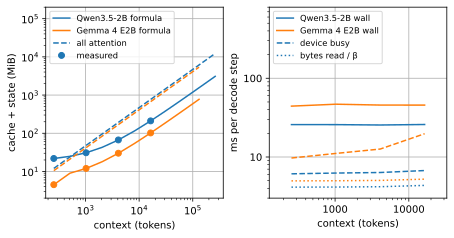

In [38]:
if not GPU:  # the rows of the run behind the published figure
    with open(d2l.download('lm-hf-memory-speed-v2',
                           os.path.join('..', 'data', 'lm'))) as f:
        measured = json.load(f)
curves = {'mem': {}, 'time': {}}  # (panel, model, style): (x, y)
for m, c in configs.items():
    rows = [r for r in measured['rows'] if r['model'] == m]
    n_run = [r['n'] for r in rows]
    ns = [2**k for k in range(
        8, c.get_text_config().max_position_embeddings.bit_length())]
    mem = [config_memory(c, n, 1) for n in ns]
    curves['mem'] |= {
        (m, '-'): (ns, [(f['kv_cache'] + f['recurrent_state']) / MiB
                        for f in mem]),
        (m, '--'): (ns, [config_memory(all_attention(c), n, 1,
                                       window_cached=n)['kv_cache'] / MiB
                         for n in ns]),
        (m, 'o'): (n_run, [r['walker_logical'] / MiB for r in rows])}
    curves['time'] |= {(m, style): (n_run, [r[k] for r in rows])
                       for k, style in (('wall_ms_median', '-'),
                                        ('busy_ms', '--'),
                                        ('r_over_beta_measured_ms', ':'))}
# The solid curves of both models, then the first model's other curves: a
# legend of four names the models by colour and the rest by line style
_, axes = d2l.plt.subplots(1, 2, figsize=(6.2, 3.2), layout='constrained')
color = {QWEN: 'C0', GEMMA: 'C1'}
for ax, panel, ylabel, xlim, ylim, solid, styles in (  # both axes log
        (axes[0], 'mem', 'cache + state (MiB)', None, (2, 2e5), 'formula',
         {'--': 'all attention', 'o': 'measured'}),
        (axes[1], 'time', 'ms per decode step', (128, 32768), (3, 800),
         'wall', {'--': 'device busy', ':': 'bytes read / β'})):
    keys = ([(QWEN, '-'), (GEMMA, '-')] + [(QWEN, s) for s in styles]
            + [(GEMMA, s) for s in styles])
    X, Y = zip(*(curves[panel][k] for k in keys))
    with d2l.plt.rc_context({'legend.fontsize': 'small'}):
        d2l.plot(list(X), list(Y), 'context (tokens)', ylabel,
                 [f'{NAMES[QWEN]} {solid}', f'{NAMES[GEMMA]} {solid}',
                  *styles.values()], xlim=xlim, ylim=ylim, xscale='log',
                 yscale='log', fmts=[color[m] + s for m, s in keys],
                 axes=ax, legend_loc='upper left')

<!-- d2l:prose id=hf-models-md-35 fw=all -->

Both panels have logarithmic axes, so equal distances on them are equal
ratios. On the left, the measured points lie on the lines derived from the
configuration. The hybrid starts nearly flat, just above its 18.8 MiB of
state, and crosses below its dashed all-attention line at 536 tokens. On the
right, the three curves of each model keep one order at every context: the
dotted bound $R(n) / \beta$ lies below the dashed GPU time, and the GPU time
below the solid wall time. For Qwen3.5-2B all three are level, at about 4, 6
and 26 ms, and the widest gap is the one between the GPU and the clock. Only
one curve of the panel bends. Gemma's GPU time doubles towards 16,384
tokens, and the wall time above it does not notice.

Everything in this section ran on modeling code that we did not write and
have not read. Qwen3, the family before Qwen3.5, has attention in every
layer and differs from the transformer block of this book in a short list of
places. That invites a test: would its released tensors run in the book's
own code, and agree with Transformers layer by layer
(that section)?

## Summary

A released model is one commit of a repository: a configuration, a tokenizer
with its chat template, and tensors, run by code that lives in the library.
A load that can be repeated therefore pins the commit, checks which tensors
were loaded, and passes its sampling arguments explicitly. The configuration
fixes every shape, and from its fields we counted, before any download, the
parameters, the memory of each sequence as a slope per token plus a
constant, and the bytes that a decode step must read. The activations of a
prefill, the largest term for a long prompt, we could only estimate, and
only for the kernels in use. With fused kernels and an allocator that does
not fragment, the GPU confirmed the memory to within a few percent. For the
speed of writing the configuration gives only a bound, 4 to 5 ms per token
here. The eager loop of Transformers takes 26 ms for Qwen3.5-2B and 44 to
49 ms for Gemma 4 E2B, because the host spends about 15 µs on each of
thousands of kernel launches.

## Exercises

1. [code] **Two files for one architecture.** The post-trained Qwen3-0.6B
   and its base model have the same architecture, yet the weight files
   listed in that section differ by a quarter in size.
    1. Read both headers with `d2l.safetensors_header` and find the tensor
       that accounts for the difference.
    1. Predict what `model.num_parameters()` and `len(model.state_dict())`
       return for each of the two models after `d2l.load_hf`, then check.
       Which of the two counts a tied tensor twice?

1. [code] **The end of a turn.** Load Qwen3.5-2B with `d2l.load_hf` and ask
   it a question that has a short answer
   (that section).
    1. Render the question with `add_generation_prompt=False`. Predict from
       the last tokens of this prompt what the model will write first, then
       generate and check.
    1. The text says that without the stop token that `d2l.load_hf` adds,
       this model stops two tokens after its turn. Remove token 248046 from
       `model.generation_config.eos_token_id`, generate greedily with a
       limit of 200 new tokens, and decode the reply with
       `skip_special_tokens=False`. Then sample twenty replies at
       temperature 1 and twenty at temperature 1.5. Among the replies that
       reach `<|im_end|>`, does every one stop two tokens later? What
       happened to the others?

1. [code] **Two rules for combined truncation.** Transformers applies
   top-$k$ and then applies top-$p$ to the renormalized distribution. The
   `sample_next` function of that section computes both cutoffs on
   the full distribution and keeps the smaller count.
    1. For the probabilities $(0.4, 0.3, 0.2, 0.1)$, a top-$k$ of 3 and a
       top-$p$ of 0.75, how many tokens does each rule keep? Show that the
       sequential rule never keeps more tokens than the other one. For
       which distributions do the two keep the same set?
    1. Collect the next-token distributions of Qwen3.5-2B at 1,000
       positions of *The Time Machine*. With Gemma's defaults, a top-$k$ of
       64 followed by a top-$p$ of 0.95, at how many positions do the two
       rules keep different sets (Transformers' `TopKLogitsWarper` and
       `TopPLogitsWarper` implement the sequential one)? How much
       probability does the sequential rule discard at those positions?

1. **The cache of Gemma 4 E2B.** Use the fields of the configuration
   printed in that section.
    1. Derive the cache bytes per token of Gemma 4 E2B in bf16 for contexts
       beyond its window, and the constant that its sliding layers add.
       Check both against the line that the cell of the memory table prints
       for this model in that section.
    1. At which context would the cache of one sequence equal the bytes of
       the per-layer embedding table? Compare the answer with the model's
       maximum context.
    1. At the maximum context, how many sequences does it take for their
       caches to outweigh the table? Which term dominates the memory of
       this model when it serves one user, and which when it serves many?

1. **Crossover contexts.** ● The cache and state of Qwen3.5-2B fall below
   the cache of an all-attention model beyond 536 tokens.
    1. Express the crossover context $n^*$ through the symbols of
       the table for a hybrid in which one layer in $r$ is
       full attention. Which fields move $n^*$, and in which direction?
    1. Compute $n^*$ from the configuration of Qwen3.5-4B with
       `d2l.config_memory`.
    1. The recurrent state is read and written at every decode step, and
       the cache need only be read. For many long requests on one GPU,
       which limit does a hybrid reach first, the memory of the GPU or the
       bytes it can move per step? (The exercise on batched decoding below
       measures the second.)

1. [code] **Prediction before the download.** Qwen3.5-4B had no part in
   this section's formulas. Do not load it until the last part.
    1. Count its parameters by hand from its configuration, with
       the equation and the table, and compare
       with `d2l.config_params`. Read the head fields with care: they do
       not repeat the pattern of Qwen3.5-2B.
    1. Use `d2l.config_memory` to predict the memory of a prefill of 1 to
       4 sequences of 32,768 tokens. How many fit a budget of 15 GiB, and
       how many a GPU with 24 GB?
    1. Load the model with `d2l.load_hf` and prefill the largest number of
       such sequences that your prediction allows on a GPU with 24 GB.
       Compare the parameters, the cache and the peak above the weights,
       measured as in that section, with your
       prediction. If the largest batch runs out of memory although the
       formula's total stays below the memory the device reports, find out
       what holds the difference: which memory on the card belongs to no
       tensor of the model, and how much room should a prediction leave
       for it?

1. [code] **Batched decoding of a hybrid.** A decode step of $B$ sequences
   reads the weights once and the cache and state of every sequence
   (that section).
    1. From the equation, derive the batch size $B^*(n)$
       at which the caches and states of the batch equal the weights in
       bytes read, for Qwen3.5-2B and for its all-attention counterpart.
       Evaluate both at $n = 1{,}024$ and at $n = 16{,}384$.
    1. Measure the time of a decode step of Qwen3.5-2B for batch sizes from
       1 to 32 at a context of 1,024 tokens. Where does the time per step
       begin to grow? Explain the result with the share of the step for
       which the GPU is busy and the launch count of
       that section, and compare it with $B^*$.

1. [code] **A table on the host.** ● The per-layer embedding table of
   Gemma 4 E2B is looked up, never multiplied.
    1. Predict the GPU memory that is saved by keeping the table in host
       memory, and the bytes that then cross from the host to the GPU at
       every decode step and for a prompt of 4,096 tokens.
    1. Move the module `gemma.get_per_layer_input_embeddings()` to the CPU.
       Give it a forward pre-hook that moves the token ids to the CPU and a
       forward hook that moves the rows it returns to the GPU. Measure the
       memory and the time of a prefill and of a decode step. Was time lost
       where you predicted it?

1. [code] **The cost of a mask.** The text claims that a Boolean mask of
   $n^2$ bytes costs $3n^2$ bytes while PyTorch's fused attention uses it.
    1. Call `F.scaled_dot_product_attention` on random bf16 queries, keys
       and values with 8 heads of width 256 at $n = 4{,}096$, $8{,}192$ and
       $16{,}384$ positions, once with `is_causal=True` and once with the
       causal rule as a Boolean mask of shape $(n, n)$. Measure the peak
       memory of each call and fit the difference to $c_2 n^2 + c_1 n$
       bytes. Is $c_2$ the two bytes per pair of the text?
    1. For a prefill of Gemma 4 E2B, the comparison in the text prints the
       reference's peak minus the fused one as 1.00 $n^2$ bytes at 16,384
       tokens and as 1.15 $n^2$ at 32,768. The text explains the step by
       the place of the peak: a double-wide MLP at the shorter length, the
       attention of a sliding layer at the longer. Check this inside
       `d2l.reference_kernels` with forward hooks that record the peak
       memory within each attention module and each MLP, at 16,384, 24,576
       and 32,768 tokens. On which side of the step does 24,576 fall?
    1. Predict the longest prompt that the reference code can prefill on a
       GPU with 24 GB, then find it by a search in steps of 4,096 tokens.

1. [extended] **A model passport.** ●● Write a function that takes a model
   id and prints, from `config.json` and the safetensors headers alone: the
   parameters by group, the bytes of weights, of cache and of state for a
   workload of your choice, the license and whether the repository is
   gated, and every field of the configuration that your function does not
   understand. Run it on five recent models of different families. Which
   fields break it, and which of them change the memory?